# TAHAP 2 — Model Terbaik per Pendekatan + Perbandingan Data Prep (Standalone)

Notebook baru, terpisah dari `code.ipynb` (arsip percobaan awal buat lampiran skripsi).

**Tujuan tahap ini:**
1. Metrik utama: **RMSE** (bukan MAPE) — alasan di markdown metrik di bawah.
2. Bandingkan **4 varian data-prep** (baseline/cap+smooth, Savitzky-Golay, RobustScaler, Yeo-Johnson) x **3 model** (ARIMAX/GB/LSTM) x **2 pendekatan** (per-unit/per-kriteria) = 24 kombinasi kandidat, semua di-rank pakai RMSE_GLOBAL.
3. Tentukan pendekatan+model+data-prep terbaik secara terpisah untuk per-unit dan per-kriteria.
4. (Tahap 3, menyusul) Tuning individual per-unit & per-kriteria pakai kombinasi pemenang.

In [1]:
import pandas as pd
import numpy as np
import warnings
import json
from pathlib import Path

warnings.filterwarnings('ignore')

UPLOAD_DIR = Path('.')
OUT_DIR = Path('./checkpoints_v2')          # folder BARU, terpisah dari checkpoints lama
MAP_DIR = Path('./anonymization_maps')      # tetap sama - deterministik, aman dipakai bareng
OUT_DIR.mkdir(exist_ok=True)
MAP_DIR.mkdir(exist_ok=True)

BBM_FILES = {
    2023: UPLOAD_DIR / 'BBM AAB 2023.xlsx',
    2024: UPLOAD_DIR / 'BBM AAB 2024.xlsx',
    2025: UPLOAD_DIR / 'BBM AAB 2025.xlsx',
}
CONTAINER_FILES = {
    2023: UPLOAD_DIR / 'Container 2023.xlsx',
    2024: UPLOAD_DIR / 'Container 2024.xlsx',
    2025: UPLOAD_DIR / 'Container 2025.xlsx',
}
COST_FILE = UPLOAD_DIR / 'cost & bbm 2022 sd 2025 HP & Type.xlsx'
RAINFALL_FILE = UPLOAD_DIR / 'Curah Hujan 2023-2025.xlsx'

TRAIN_END = pd.Period('2024-12', freq='M')
TEST_START = pd.Period('2025-01', freq='M')


## Preprocessing (copy identik dari `code.ipynb` yang sudah fixed, populasi final pasca-restrukturisasi)

In [2]:
def scan_bbm_unit_names(bbm_files):
    units = set()
    for yr, path in bbm_files.items():
        xls = pd.ExcelFile(path)
        for sh in xls.sheet_names:
            df = pd.read_excel(path, sheet_name=sh, header=[0, 1, 2], nrows=1)
            if df.empty:
                continue
            level0 = df.columns.get_level_values(0)
            for l0 in set(level0):
                if l0 == 'EQUIP NAME':
                    continue
                subcols = set(df.columns[level0 == l0].get_level_values(2))
                if 'HM' in subcols and 'LITER' in subcols:
                    units.add(l0)
    return units

def scan_container_branch_codes(container_files):
    branches = set()
    for yr, path in container_files.items():
        df = pd.read_excel(path, sheet_name=0, header=None)
        col0 = df.iloc[:, 0]
        starts = col0[col0 == 'CURRSTATE'].index.tolist()
        for i, s in enumerate(starts):
            end = starts[i + 1] if i + 1 < len(starts) else len(df)
            data_start = s + 9
            block_col0 = df.iloc[data_start:end, 0]
            gt_idx = block_col0[block_col0 == 'Grand Total'].index
            data_end = gt_idx[0] if len(gt_idx) > 0 else end
            branches.update(df.iloc[data_start:data_end, 0].dropna().unique().tolist())
    return branches

def scan_cost_file_names_and_lokasi(cost_file):
    df = pd.read_excel(cost_file, sheet_name='Sheet2', header=1)
    names = set(df['NAMA ALAT BERAT'].dropna().unique().tolist())
    lokasi = set(df['DES 2025'].dropna().unique().tolist())
    return names, lokasi

print('Scanning BBM AAB unit names...')
bbm_units = scan_bbm_unit_names(BBM_FILES)
print('Scanning Container branch codes...')
branch_codes = scan_container_branch_codes(CONTAINER_FILES)
print('Scanning cost&bbm file...')
cost_names, cost_lokasi = scan_cost_file_names_and_lokasi(COST_FILE)

all_unit_names = sorted(bbm_units | cost_names)
unit_map = {name: f'UNIT_{i+1:04d}' for i, name in enumerate(all_unit_names)}

branch_map = {name: f'BRANCH_{i+1:03d}' for i, name in enumerate(sorted(branch_codes))}
lokasi_map = {name: f'LOC_{i+1:03d}' for i, name in enumerate(sorted(cost_lokasi))}

print(f'Total unit: {len(unit_map)} | branch cabang: {len(branch_map)} | lokasi: {len(lokasi_map)}')

with open(MAP_DIR / 'unit_map.json', 'w') as f:
    json.dump(unit_map, f, indent=2, ensure_ascii=False)
with open(MAP_DIR / 'branch_map.json', 'w') as f:
    json.dump(branch_map, f, indent=2, ensure_ascii=False)
with open(MAP_DIR / 'lokasi_map.json', 'w') as f:
    json.dump(lokasi_map, f, indent=2, ensure_ascii=False)

Scanning BBM AAB unit names...
Scanning Container branch codes...
Scanning cost&bbm file...
Total unit: 355 | branch cabang: 49 | lokasi: 35


In [3]:
def process_bbm_sheet(path, sheet, unit_map):
    df = pd.read_excel(path, sheet_name=sheet, header=[0, 1, 2])
    if df.empty or df.shape[1] == 0:
        return None

    cols = df.columns
    level0 = cols.get_level_values(0)

    tgl_col = next((c for c in cols if c[2] == 'TANGGAL'), None)
    if tgl_col is None:
        return None

    unit_cols = []
    for l0 in set(level0):
        if l0 == 'EQUIP NAME':
            continue
        subcols = set(cols[level0 == l0].get_level_values(2))
        if 'HM' in subcols and 'LITER' in subcols:
            for c in cols[level0 == l0]:
                if c[2] in ('HM', 'LITER'):
                    unit_cols.append(c)

    if not unit_cols:
        return None

    sub = df[[tgl_col] + unit_cols].copy()
    sub.columns = pd.MultiIndex.from_tuples([('__TANGGAL__', '', '')] + list(sub.columns[1:]))

    tgl_raw = sub[('__TANGGAL__', '', '')].astype(str)
    sub = sub[~tgl_raw.isin(['AVG', 'TOTAL LTR/UTL', 'nan'])]

    sub = sub.set_index(('__TANGGAL__', '', ''))
    sub.index.name = 'TANGGAL'
    sub.columns = pd.MultiIndex.from_tuples([(c[0], c[2]) for c in sub.columns])

    long_df = sub.stack(level=0, future_stack=True).reset_index()
    long_df = long_df.rename(columns={'level_1': 'EQUIP NAME'})
    long_df['EQUIP NAME'] = long_df['EQUIP NAME'].map(unit_map)
    return long_df


frames = []
for yr, path in BBM_FILES.items():
    xls = pd.ExcelFile(path)
    for sh in xls.sheet_names:
        r = process_bbm_sheet(path, sh, unit_map)
        if r is not None:
            frames.append(r)

raw_bbm = pd.concat(frames, ignore_index=True)
print('raw_bbm shape:', raw_bbm.shape)
raw_bbm.head()

raw_bbm shape: (333643, 4)


,TANGGAL,EQUIP NAME,HM,LITER
0,01-01-2023,UNIT_0049,0.0,0.0
1,01-01-2023,UNIT_0070,20641.5,0.0
2,01-01-2023,UNIT_0313,0.0,0.0
3,01-01-2023,UNIT_0123,11710.0,0.0
4,01-01-2023,UNIT_0034,0.0,0.0


In [4]:
print(raw_bbm['EQUIP NAME'].nunique(), 'unit unik')
print(raw_bbm.dtypes)

306 unit unik
TANGGAL        object
EQUIP NAME     object
HM            float64
LITER         float64
dtype: object


In [5]:
raw_bbm['TANGGAL'] = pd.to_datetime(raw_bbm['TANGGAL'], format='%d-%m-%Y', errors='coerce')
raw_bbm = raw_bbm.dropna(subset=['TANGGAL'])
print('shape setelah date clean:', raw_bbm.shape)

shape setelah date clean: (333643, 4)


In [6]:
raw_bbm['HM_Clean'] = pd.to_numeric(raw_bbm['HM'], errors='coerce')
raw_bbm['HM_Clean'] = raw_bbm['HM_Clean'].replace(0, np.nan)
raw_bbm['HM_Clean'] = raw_bbm.groupby('EQUIP NAME')['HM_Clean'].ffill()
raw_bbm['HM_Clean'] = raw_bbm['HM_Clean'].fillna(0)

raw_bbm['DELTA_HM'] = raw_bbm.groupby('EQUIP NAME')['HM_Clean'].diff().fillna(0)
raw_bbm.loc[raw_bbm['DELTA_HM'] < 0, 'DELTA_HM'] = 0        # reset sensor/salah catat -> 0
raw_bbm.loc[raw_bbm['DELTA_HM'] > 24, 'DELTA_HM'] = 24       # FIX (saran dosen): >24 jam/hari -> cap ke 24, bukan buang ke 0

raw_bbm.to_csv(OUT_DIR / '01_daily_delta_hm.csv', index=False)
raw_bbm[['EQUIP NAME','TANGGAL','HM_Clean','DELTA_HM']].head()

,EQUIP NAME,TANGGAL,HM_Clean,DELTA_HM
0,UNIT_0049,2023-01-01,0.0,0.0
1,UNIT_0070,2023-01-01,20641.5,0.0
2,UNIT_0313,2023-01-01,0.0,0.0
3,UNIT_0123,2023-01-01,11710.0,0.0
4,UNIT_0034,2023-01-01,0.0,0.0


In [7]:
raw_bbm['TAHUN_BULAN'] = raw_bbm['TANGGAL'].dt.to_period('M')
monthly_hm = (raw_bbm.groupby(['EQUIP NAME', 'TAHUN_BULAN'])['DELTA_HM']
              .sum().round(1).reset_index().rename(columns={'DELTA_HM': 'UTILITAS'}))

monthly_hm.to_csv(OUT_DIR / '02_monthly_utilitas.csv', index=False)
print(monthly_hm.shape, '| range:', monthly_hm['TAHUN_BULAN'].min(), '-', monthly_hm['TAHUN_BULAN'].max())
monthly_hm.head()

(10959, 3) | range: 2023-01 - 2025-12


,EQUIP NAME,TAHUN_BULAN,UTILITAS
0,UNIT_0001,2023-01,0.0
1,UNIT_0001,2023-02,0.0
2,UNIT_0001,2023-03,0.0
3,UNIT_0001,2023-04,0.0
4,UNIT_0001,2023-05,0.0


In [8]:
MONTH_MAP = {'Jan':1,'Feb':2,'Mar':3,'Apr':4,'May':5,'Jun':6,
             'Jul':7,'Aug':8,'Sep':9,'Oct':10,'Nov':11,'Dec':12}

TARGET_CURRSTATE = {'FXD', 'FAC', 'STR', 'MAS', 'MTB', 'FOB', 'MXD', 'MOB'}

PREFERRED_PREV = {
    'FXD': 'All', 'FAC': 'All', 'STR': 'All', 'MAS': 'All',
    'MTB': 'All', 'FOB': 'All', 'MXD': 'All', 'MOB': 'MTL',
}

VALID_CONTAINER_TYPES = {
    '10 CO', '10 DC', '20 CO', '20 DC', '20 FT', '20 HC', '20 IT', '20 OT', '20 RF', '20 RH', '20 RM',
    '21 DC', '40 CO', '40 DC', '40 FT', '40 HC', '40 IT', '40 OT', '40 RF', '40 RH', '40 RM', '41 DC', '45 HC',
}

def parse_container_file(path, branch_map, target_currstate=TARGET_CURRSTATE, preferred_prev=PREFERRED_PREV):
    df = pd.read_excel(path, sheet_name=0, header=None)
    col0 = df.iloc[:, 0]
    starts = col0[col0 == 'CURRSTATE'].index.tolist()

    monthly_totals = {m: 0.0 for m in range(1, 13)}
    branch_rows_log = []
    blocks_used = []

    for i, s in enumerate(starts):
        curr = df.iloc[s, 1]
        prev = df.iloc[s + 1, 1]
        if curr not in target_currstate or prev != preferred_prev.get(curr):
            continue
        blocks_used.append((curr, prev))

        end = starts[i + 1] if i + 1 < len(starts) else len(df)
        coc_row = df.iloc[s + 6, :].copy()
        month_row = df.iloc[s + 7, :].copy()
        type_row = df.iloc[s + 8, :]
        coc_row.iloc[1:] = coc_row.iloc[1:].ffill()
        month_row.iloc[1:] = month_row.iloc[1:].ffill()

        data_start = s + 9
        block_col0 = df.iloc[data_start:end, 0]
        gt_idx = block_col0[block_col0 == 'Grand Total'].index
        data_end = gt_idx[0] if len(gt_idx) > 0 else end
        branch_rows = df.iloc[data_start:data_end]

        for col_idx in range(1, df.shape[1]):
            mon = month_row.iloc[col_idx]
            typ = type_row.iloc[col_idx]
            if pd.isna(mon) or mon not in MONTH_MAP:
                continue
            if typ not in VALID_CONTAINER_TYPES:
                continue
            vals = pd.to_numeric(branch_rows.iloc[:, col_idx], errors='coerce').fillna(0)
            monthly_totals[MONTH_MAP[mon]] += vals.sum()

            for r_idx in range(len(branch_rows)):
                branch_raw = branch_rows.iloc[r_idx, 0]
                if pd.isna(branch_raw):
                    continue
                v = vals.iloc[r_idx]
                if v != 0:
                    branch_rows_log.append({
                        'CABANG': branch_map.get(branch_raw, branch_raw),
                        'CURRSTATE': curr, 'BULAN': MONTH_MAP[mon],
                        'TIPE_CONTAINER': typ, 'VOLUME': v,
                    })

    return monthly_totals, pd.DataFrame(branch_rows_log), blocks_used

container_monthly_frames = []
container_branch_checkpoints = []
for yr, path in CONTAINER_FILES.items():
    totals, branch_df, used = parse_container_file(path, branch_map)
    print(yr, 'blok dipakai:', used, '| total tahun:', sum(totals.values()))
    for m, v in totals.items():
        container_monthly_frames.append({'TAHUN_BULAN': pd.Period(f'{yr}-{m:02d}', freq='M'), 'VOLUME_CONTAINER': v})
    branch_df['TAHUN'] = yr
    container_branch_checkpoints.append(branch_df)

monthly_container = pd.DataFrame(container_monthly_frames).sort_values('TAHUN_BULAN').reset_index(drop=True)
container_branch_detail = pd.concat(container_branch_checkpoints, ignore_index=True)

monthly_container.to_csv(OUT_DIR / '03a_monthly_container.csv', index=False)
container_branch_detail.to_csv(OUT_DIR / '03a_container_per_cabang_detail.csv', index=False)
monthly_container

2023 blok dipakai: [('FXD', 'All'), ('FAC', 'All'), ('STR', 'All'), ('MAS', 'All'), ('MTB', 'All'), ('FOB', 'All'), ('MXD', 'All'), ('MOB', 'MTL')] | total tahun: 4330703.0
2024 blok dipakai: [('FXD', 'All'), ('FAC', 'All'), ('STR', 'All'), ('MAS', 'All'), ('MTB', 'All'), ('FOB', 'All'), ('MXD', 'All'), ('MOB', 'MTL')] | total tahun: 4323469.0
2025 blok dipakai: [('FXD', 'All'), ('FAC', 'All'), ('STR', 'All'), ('MAS', 'All'), ('MTB', 'All'), ('FOB', 'All'), ('MXD', 'All'), ('MOB', 'MTL')] | total tahun: 4012779.0


,TAHUN_BULAN,VOLUME_CONTAINER
0,2023-01,368115.0
1,2023-02,355535.0
2,2023-03,350609.0
3,2023-04,296614.0
4,2023-05,365756.0
5,2023-06,347347.0
6,2023-07,370061.0
7,2023-08,371458.0
8,2023-09,372757.0
9,2023-10,396370.0


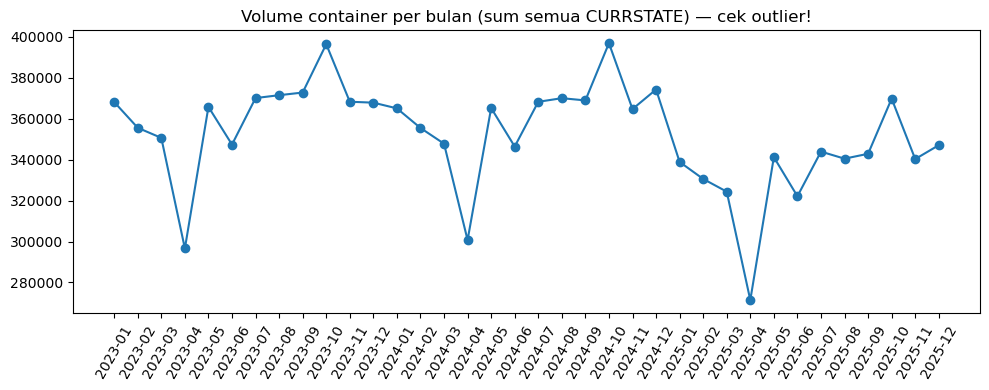

       VOLUME_CONTAINER
count         36.000000
mean      351859.750000
std        25862.723744
min       271398.000000
25%       341021.000000
50%       355495.000000
75%       368425.750000
max       396862.000000


In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(monthly_container['TAHUN_BULAN'].astype(str), monthly_container['VOLUME_CONTAINER'], marker='o')
ax.set_title('Volume container per bulan (sum semua CURRSTATE) — cek outlier!')
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

print(monthly_container.describe())

In [10]:
rain = pd.read_excel(RAINFALL_FILE, header=3)
rain = rain.rename(columns={'precipitation_sum (mm)': 'precipitation_sum'})
rain['time'] = pd.to_datetime(rain['time'])
rain = rain.set_index('time')

monthly_rain = rain['precipitation_sum'].resample('ME').sum().round(1).reset_index()

monthly_rain['TAHUN_BULAN'] = monthly_rain['time'].dt.to_period('M')
monthly_rain = monthly_rain[['TAHUN_BULAN', 'precipitation_sum']].rename(columns={'precipitation_sum': 'CURAH_HUJAN'})

monthly_full = monthly_hm.merge(monthly_rain, on='TAHUN_BULAN', how='left')
monthly_full = monthly_full.merge(monthly_container, on='TAHUN_BULAN', how='left')

# ── RESTRUKTURISASI (susulan): populasi unit resmi = ADA di cost & bbm HP&Type SAJA ──
# unit_map (Cell 1) dibangun dari UNION nama BBM AAB + nama cost&bbm -> exact match ke unit_map
# BISA "berhasil" walau ID-nya gak py data BBM asli (nama plat lama yang cuma nongol di cost&bbm).
# Jadi exact-match harus dicek py data BBM ASLI dulu sebelum dianggap valid.
import re
from difflib import get_close_matches

cost_df = pd.read_excel(COST_FILE, sheet_name='Sheet2', header=1)
kriteria_raw = cost_df[['NAMA ALAT BERAT', 'DES 2025', 'ALAT BERAT', 'TYPE/MERK', 'CAP', 'HP']].copy()
kriteria_raw = kriteria_raw.rename(columns={'DES 2025': 'LOKASI_RAW', 'ALAT BERAT': 'JENIS'})

# Nickname/singkatan yang gak ketangkep otomatis lewat "EX." atau sebelum kurung (dikonfirmasi manual user):
MANUAL_OVERRIDE = {
    'TOP LOADER KALMAR 35 T/TOBATI': 'TOBATI (EX.FL KALMAR 32T)',
    'L 9902 UR / S75': 'L 8477 UUC (EX.L 9902 UR)',
    'TOP LOADER BOSS': 'WIND RIVER (EX.TL BOSS 42T)',
}
# Catatan: FALCON sengaja TIDAK match ke cost&bbm — alat elektrik, tidak punya HP (BBM/diesel),
# dan juga tidak punya data BBM AAB sama sekali. Expected, bukan bug.

def extract_after_ex(name):
    m = re.search(r'EX\.\s*([^)]+)\)', str(name), re.IGNORECASE)
    return m.group(1).strip() if m else None

def extract_before_paren(name):
    name = str(name)
    return name.split('(')[0].strip() if '(' in name else None

unit_ids_with_data = set(monthly_hm['EQUIP NAME'].unique())  # ID yang BENERAN punya baris data BBM

# alias dibangun HANYA dari nama BBM AAB yang beneran py data (buang ghost dari union cost_names)
alias_after_ex, alias_before_paren = {}, {}
for full_name, uid in unit_map.items():
    if uid not in unit_ids_with_data:
        continue
    after = extract_after_ex(full_name)
    if after:
        alias_after_ex.setdefault(after.upper(), full_name)
    before = extract_before_paren(full_name)
    if before:
        alias_before_paren.setdefault(before.upper(), full_name)

def resolve_to_data_bearing_unit(nama_cost):
    nama_cost = str(nama_cost).strip()
    uid = unit_map.get(nama_cost)
    if uid and uid in unit_ids_with_data:
        return nama_cost, 'exact'
    if nama_cost in MANUAL_OVERRIDE and unit_map.get(MANUAL_OVERRIDE[nama_cost]) in unit_ids_with_data:
        return MANUAL_OVERRIDE[nama_cost], 'manual_override'
    upper = nama_cost.upper()
    if upper in alias_after_ex:
        return alias_after_ex[upper], 'match_after_EX'
    if upper in alias_before_paren:
        return alias_before_paren[upper], 'match_before_paren'
    return None, 'unmatched'

resolved = kriteria_raw['NAMA ALAT BERAT'].apply(
    lambda x: pd.Series(resolve_to_data_bearing_unit(x), index=['NAMA_RESOLVED', 'METODE_MATCH'])
)
kriteria_raw = pd.concat([kriteria_raw, resolved], axis=1)
kriteria_raw['EQUIP NAME'] = kriteria_raw['NAMA_RESOLVED'].map(unit_map)
kriteria_raw['LOKASI'] = kriteria_raw['LOKASI_RAW'].map(lokasi_map)

print('Ringkasan metode matching cost&bbm -> unit BBM AAB (yang beneran punya data):')
print(kriteria_raw['METODE_MATCH'].value_counts())

unmatched_cost = kriteria_raw[kriteria_raw['EQUIP NAME'].isna()]
print(f'\n{len(unmatched_cost)} baris di cost&bbm TIDAK ketemu pasangan unit BBM AAB berdata.')
if len(unmatched_cost) > 0:
    bbm_names_with_data = [n for n, u in unit_map.items() if u in unit_ids_with_data]
    print('Kandidat kemiripan nama (fuzzy match) buat dicek manual:')
    for nama in unmatched_cost['NAMA ALAT BERAT'].dropna().unique():
        print(f'  {nama!r} -> {get_close_matches(str(nama), bbm_names_with_data, n=3, cutoff=0.5)}')

kriteria_raw = kriteria_raw.drop(columns=['NAMA ALAT BERAT', 'LOKASI_RAW', 'NAMA_RESOLVED'])
kriteria_raw['KRITERIA_ID'] = kriteria_raw[['JENIS', 'TYPE/MERK', 'CAP', 'HP']].astype(str).agg('|'.join, axis=1)
kriteria = (kriteria_raw.dropna(subset=['EQUIP NAME'])
            .drop_duplicates(subset=['EQUIP NAME'])
            .reset_index(drop=True))
kriteria.to_csv(OUT_DIR / '08_kriteria_unit.csv', index=False)

# ── Restrict monthly_full HANYA ke unit yang match ke cost & bbm HP&Type ──
unit_resmi = set(kriteria['EQUIP NAME'])
semua_unit_bbm = set(monthly_full['EQUIP NAME'].unique())
unit_dikecualikan = semua_unit_bbm - unit_resmi

inv_unit_map = {v: k for k, v in unit_map.items()}
excluded_df = pd.DataFrame([
    {'EQUIP NAME': u, 'NAMA_ASLI': inv_unit_map.get(u, u)} for u in unit_dikecualikan
]).sort_values('NAMA_ASLI')
excluded_df.to_csv(OUT_DIR / '00b_unit_tidak_ada_di_costbbm_dikecualikan.csv', index=False)

print(f'\n=== RINGKASAN POPULASI UNIT ===')
print(f'Total unit di BBM AAB (punya data): {len(semua_unit_bbm)}')
print(f'Unit match ke cost & bbm HP&Type (DIPAKAI analisa): {len(unit_resmi)}')
print(f'Unit DIKECUALIKAN (gak ada di cost & bbm HP&Type): {len(excluded_df)}')
print(excluded_df.to_string(index=False))

monthly_full = monthly_full[monthly_full['EQUIP NAME'].isin(unit_resmi)].reset_index(drop=True)
print(f'\nJumlah unit final di monthly_full: {monthly_full["EQUIP NAME"].nunique()}')

monthly_full.to_csv(OUT_DIR / '04_monthly_with_exog.csv', index=False)
monthly_full.head()


Ringkasan metode matching cost&bbm -> unit BBM AAB (yang beneran punya data):
METODE_MATCH
exact                 196
match_after_EX         39
unmatched               5
manual_override         3
match_before_paren      2
Name: count, dtype: int64

5 baris di cost&bbm TIDAK ketemu pasangan unit BBM AAB berdata.
Kandidat kemiripan nama (fuzzy match) buat dicek manual:
  'FALCON' -> ['KALONG', 'ALPINE']
  'L9582UQ' -> ['L 9583 UQ', 'L9120UQ', 'L 9118 UQ']
  'TN05' -> []
  'TRAILER' -> ['XAVIER', 'RANGER', 'RAFLESIA']
  'TRONTON PK 215' -> []

=== RINGKASAN POPULASI UNIT ===
Total unit di BBM AAB (punya data): 306
Unit match ke cost & bbm HP&Type (DIPAKAI analisa): 240
Unit DIKECUALIKAN (gak ada di cost & bbm HP&Type): 66
EQUIP NAME                       NAMA_ASLI
 UNIT_0025                        CONVEY01
 UNIT_0029        CRANE RENTAL 01 SURABAYA
 UNIT_0030        CRANE RENTAL 02 SURABAYA
 UNIT_0031          DUMMY (JANGAN DIPAKAI)
 UNIT_0034                    FL RENTAL 01
 UNIT_0035    

,EQUIP NAME,TAHUN_BULAN,UTILITAS,CURAH_HUJAN,VOLUME_CONTAINER
0,UNIT_0001,2023-01,0.0,254.7,368115.0
1,UNIT_0001,2023-02,0.0,362.1,355535.0
2,UNIT_0001,2023-03,0.0,273.7,350609.0
3,UNIT_0001,2023-04,0.0,243.4,296614.0
4,UNIT_0001,2023-05,0.0,76.1,365756.0


In [11]:
completeness = (monthly_full.groupby('EQUIP NAME')['TAHUN_BULAN']
                 .agg(['min', 'max', 'count'])
                 .rename(columns={'min': 'BULAN_AWAL', 'max': 'BULAN_AKHIR', 'count': 'JUMLAH_BULAN'}))
completeness['KONDISI'] = np.where(completeness['JUMLAH_BULAN'] >= 36, 'DATA_PENUH', 'DATA_PARSIAL')
completeness.to_csv(OUT_DIR / '05_completeness_per_unit.csv')
completeness['KONDISI'].value_counts()

KONDISI
DATA_PENUH    240
Name: count, dtype: int64

In [12]:
def filter_units(df, train_end=TRAIN_END, test_start=TEST_START):
    excluded = []
    keep_units = []
    for unit, g in df.groupby('EQUIP NAME'):
        train_g = g[g['TAHUN_BULAN'] <= train_end]
        test_g = g[g['TAHUN_BULAN'] >= test_start]

        if test_g.empty or test_g['UTILITAS'].isna().all():
            excluded.append((unit, 'tidak ada data aktual pada test'))
            continue
        if len(train_g) < 12 or len(test_g) < 12:
            excluded.append((unit, 'train atau test < 12 bulan'))
            continue

        train_g_years = train_g.copy()
        train_g_years['TAHUN'] = train_g_years['TAHUN_BULAN'].dt.year
        zero_year = train_g_years.groupby('TAHUN')['UTILITAS'].sum().eq(0).any()
        if zero_year:
            excluded.append((unit, 'nol total di salah satu tahun train'))
            continue
        if test_g['UTILITAS'].sum() == 0:
            excluded.append((unit, 'test bernilai nol seluruhnya'))
            continue

        keep_units.append(unit)

    return keep_units, pd.DataFrame(excluded, columns=['EQUIP NAME', 'ALASAN_EXCLUDE'])

keep_units, excluded_df = filter_units(monthly_full)
excluded_df.to_csv(OUT_DIR / '06_excluded_units.csv', index=False)
print(f'{len(keep_units)} unit lolos filter, {len(excluded_df)} unit dikecualikan')

df_model = monthly_full[monthly_full['EQUIP NAME'].isin(keep_units)].copy()
train_df = df_model[df_model['TAHUN_BULAN'] <= TRAIN_END].copy()
test_df = df_model[df_model['TAHUN_BULAN'] >= TEST_START].copy()

train_df.to_csv(OUT_DIR / '07_train.csv', index=False)
test_df.to_csv(OUT_DIR / '07_test.csv', index=False)
print('train:', train_df.shape, '| test:', test_df.shape)

222 unit lolos filter, 18 unit dikecualikan
train: (5328, 5) | test: (2664, 5)


In [13]:
# Simpan salinan RAW (belum di-smooth/di-transform) — jadi titik awal buat semua varian data-prep
train_df_raw = train_df.copy()
test_df_raw = test_df.copy()

train_full_raw = train_df_raw.merge(kriteria[['EQUIP NAME', 'KRITERIA_ID']], on='EQUIP NAME', how='left')
test_full_raw = test_df_raw.merge(kriteria[['EQUIP NAME', 'KRITERIA_ID']], on='EQUIP NAME', how='left')

unit_list = train_full_raw['EQUIP NAME'].dropna().unique().tolist()
kriteria_list = train_full_raw['KRITERIA_ID'].dropna().unique().tolist()
print(f'{len(unit_list)} unit, {len(kriteria_list)} kriteria unik')


def get_series(df, key_col, key_val, value_col='UTILITAS_SMOOTH', agg='mean'):
    sub = df[df[key_col] == key_val]
    if key_col == 'EQUIP NAME':
        s = sub.set_index('TAHUN_BULAN')[value_col].sort_index()
    else:
        s = sub.groupby('TAHUN_BULAN')[value_col].agg(agg).sort_index()
    return s


def get_exog(df, key_col, key_val):
    sub = df[df[key_col] == key_val]
    ex = sub.groupby('TAHUN_BULAN')[['CURAH_HUJAN', 'VOLUME_CONTAINER']].mean().sort_index()
    return ex


222 unit, 76 kriteria unik


## Metrik Evaluasi — RMSE Utama, Bias Dilaporkan, MAPE Sekunder

- **RMSE** metrik UTAMA buat ranking — MAPE terbukti gak stabil (meledak 500-1000%+ untuk unit ber-actual≈0).
- **Bias (rata-rata actual - prediksi)** dilaporkan sebagai diagnostik, BUKAN target optimasi — prediksi ini dipakai buat banyak keperluan (alokasi, evaluasi, BBM, chatbot, project lain) tanpa satu arah risiko dominan, jadi targetnya **unbiased**, bukan sengaja over/underestimate.
- **MAPE** tetap dilaporkan buat pembanding, TIDAK dipakai milih model/parameter.

In [14]:
from sklearn.metrics import mean_squared_error


def eval_pred(actual, pred):
    if pred is None:
        return np.nan, np.nan, np.nan
    actual = np.asarray(actual, dtype=float)
    pred = np.asarray(pred, dtype=float)
    if len(actual) != len(pred):
        return np.nan, np.nan, np.nan
    mask = ~pd.isna(actual) & ~pd.isna(pred)
    if mask.sum() == 0:
        return np.nan, np.nan, np.nan
    a, p = actual[mask], pred[mask]
    a_safe = np.where(a == 0, np.nan, a)
    mape = np.nanmean(np.abs((a_safe - p) / a_safe)) * 100
    rmse = np.sqrt(mean_squared_error(a, p))
    bias = np.mean(a - p)
    return mape, rmse, bias


def global_metrics(preds_df, actual_col='ACTUAL', pred_col='PRED'):
    if preds_df is None or preds_df.empty:
        return {'RMSE_GLOBAL': np.nan, 'BIAS_GLOBAL': np.nan, 'MAPE_GLOBAL': np.nan}
    a = preds_df[actual_col].values.astype(float)
    p = preds_df[pred_col].values.astype(float)
    mask = ~pd.isna(a) & ~pd.isna(p)
    a, p = a[mask], p[mask]
    if len(a) == 0:
        return {'RMSE_GLOBAL': np.nan, 'BIAS_GLOBAL': np.nan, 'MAPE_GLOBAL': np.nan}
    rmse = float(np.sqrt(np.mean((a - p) ** 2)))
    bias = float(np.mean(a - p))
    a_safe = np.where(a == 0, np.nan, a)
    mape = float(np.nanmean(np.abs((a_safe - p) / a_safe)) * 100)
    return {'RMSE_GLOBAL': rmse, 'BIAS_GLOBAL': bias, 'MAPE_GLOBAL': mape}


## 4 Varian Data-Prep (dibandingkan satu-satu, bukan digabung)

1. **baseline** — cap 95th percentile + rolling mean (cara lama, dari `code.ipynb`).
2. **savgol** — Savitzky-Golay filter (puncak gak terlalu tinggi, lembah gak terlalu landai).
3. **robust** — RobustScaler per-unit (median & IQR, kurang sensitif ke outlier dibanding cap keras).
4. **yeojohnson** — PowerTransformer Yeo-Johnson per-unit (normalisasi distribusi, alternatif dari skewness-based mean/median switching).

**Penting — anti-leakage**: transformer (RobustScaler/PowerTransformer) di-`fit` cuma di TRAIN, lalu di-`transform` (bukan fit ulang) ke TEST. Hasil prediksi model untuk varian robust/yeojohnson otomatis di-inverse-transform balik ke skala jam asli sebelum dihitung RMSE/MAPE — biar semua varian bisa dibandingkan apple-to-apple dalam satuan jam.

In [15]:
from scipy.signal import savgol_filter
from sklearn.preprocessing import RobustScaler, PowerTransformer


def prep_baseline(train_df, test_df, value_col='UTILITAS', group_col='EQUIP NAME', upper_q=0.95, window=2):
    def _cap_smooth(df):
        df = df.sort_values([group_col, 'TAHUN_BULAN']).copy()

        def _cap(g):
            cap = g[value_col].quantile(upper_q)
            g[value_col + '_CAPPED'] = g[value_col].clip(upper=cap).round(2)
            return g

        df = df.groupby(group_col, group_keys=False).apply(_cap)
        df[value_col + '_SMOOTH'] = (
            df.groupby(group_col)[value_col + '_CAPPED']
              .transform(lambda s: s.rolling(window, min_periods=1).mean())
              .round(2)
        )
        return df

    return _cap_smooth(train_df), _cap_smooth(test_df), {}


def prep_savgol(train_df, test_df, value_col='UTILITAS', group_col='EQUIP NAME', window_length=5, polyorder=2):
    def _smooth(df):
        df = df.sort_values([group_col, 'TAHUN_BULAN']).copy()

        def _sg(g):
            y = g[value_col].values.astype(float)
            n = len(y)
            wl = min(window_length, n if n % 2 == 1 else n - 1)
            if wl < polyorder + 2 or wl < 3:
                g[value_col + '_SMOOTH'] = y  # data kependekan buat savgol -> pakai asli
            else:
                g[value_col + '_SMOOTH'] = np.round(savgol_filter(y, window_length=wl, polyorder=polyorder), 2)
            return g

        return df.groupby(group_col, group_keys=False).apply(_sg)

    return _smooth(train_df), _smooth(test_df), {}


def _prep_scaler_generic(train_df, test_df, scaler_cls, value_col='UTILITAS', group_col='EQUIP NAME'):
    """Fit scaler PER UNIT di TRAIN, transform (bukan fit ulang) ke TEST. Return transformers utk inverse nanti."""
    train_df = train_df.sort_values([group_col, 'TAHUN_BULAN']).copy()
    test_df = test_df.sort_values([group_col, 'TAHUN_BULAN']).copy()
    transformers = {}
    train_smooth = np.full(len(train_df), np.nan)
    test_smooth = np.full(len(test_df), np.nan)

    for unit in train_df[group_col].unique():
        tr_mask = train_df[group_col] == unit
        y_tr = train_df.loc[tr_mask, value_col].values.reshape(-1, 1).astype(float)
        if len(y_tr) < 3 or np.std(y_tr) == 0:
            train_smooth[tr_mask.values] = y_tr.flatten()
            te_mask = test_df[group_col] == unit
            if te_mask.any():
                test_smooth[te_mask.values] = test_df.loc[te_mask, value_col].values.astype(float)
            continue
        scaler = scaler_cls()
        y_tr_t = scaler.fit_transform(y_tr).flatten()
        train_smooth[tr_mask.values] = y_tr_t
        transformers[unit] = scaler
        te_mask = test_df[group_col] == unit
        if te_mask.any():
            y_te = test_df.loc[te_mask, value_col].values.reshape(-1, 1).astype(float)
            test_smooth[te_mask.values] = scaler.transform(y_te).flatten()

    train_df[value_col + '_SMOOTH'] = train_smooth
    test_df[value_col + '_SMOOTH'] = test_smooth
    return train_df, test_df, transformers


def prep_robust(train_df, test_df, value_col='UTILITAS', group_col='EQUIP NAME'):
    return _prep_scaler_generic(train_df, test_df, RobustScaler, value_col, group_col)


def prep_yeojohnson(train_df, test_df, value_col='UTILITAS', group_col='EQUIP NAME'):
    return _prep_scaler_generic(train_df, test_df,
                                 lambda: PowerTransformer(method='yeo-johnson'), value_col, group_col)


DATA_PREP_VARIANTS = {
    'baseline': prep_baseline,
    'savgol': prep_savgol,
    'robust': prep_robust,
    'yeojohnson': prep_yeojohnson,
}


def inverse_transform_pred(pred_array, unit, transformers):
    """Balikin prediksi ke skala jam asli. Identity kalau baseline/savgol atau unit gak punya transformer (data kependekan)."""
    if not transformers or unit not in transformers:
        return np.asarray(pred_array, dtype=float)
    scaler = transformers[unit]
    return scaler.inverse_transform(np.asarray(pred_array, dtype=float).reshape(-1, 1)).flatten()


## Setup Model — ARIMAX, GB (lag features), LSTM (sequence)

In [16]:
import pmdarima as pm
from sklearn.ensemble import HistGradientBoostingRegressor
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import MinMaxScaler
import itertools
from joblib import Parallel, delayed

tf.random.set_seed(42)

N_LAGS = 3


def make_lag_features(df, value_col='UTILITAS_SMOOTH', n_lags=N_LAGS):
    df = df.sort_values(['EQUIP NAME', 'TAHUN_BULAN']).copy()
    for lag in range(1, n_lags + 1):
        df[f'lag_{lag}'] = df.groupby('EQUIP NAME')[value_col].shift(lag)
    return df


FEAT_COLS = [f'lag_{i}' for i in range(1, N_LAGS + 1)] + ['CURAH_HUJAN', 'VOLUME_CONTAINER']


def make_sequences(values, seq_len):
    X, y = [], []
    for i in range(len(values) - seq_len):
        X.append(values[i:i + seq_len])
        y.append(values[i + seq_len, 0])
    return np.array(X), np.array(y)


P_RANGE, D_RANGE, Q_RANGE = range(0, 9), range(0, 5), range(0, 9)
pdq_grid = list(itertools.product(P_RANGE, D_RANGE, Q_RANGE))

gb_param_grid = {
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_iter': [100, 200, 300],
    'max_depth': [None, 3, 5, 7],
    'min_samples_leaf': [5, 10, 20],
}
gb_grid = list(itertools.product(*gb_param_grid.values()))
gb_keys = list(gb_param_grid.keys())

lstm_param_grid = {
    'seq_len': [3, 6],
    'units': [16, 32],
    'epochs': [30, 50],
}
lstm_grid = list(itertools.product(*lstm_param_grid.values()))

BATCH_SIZE = 10
print(f'PDQ grid: {len(pdq_grid)} | GB grid: {len(gb_grid)} | LSTM grid: {len(lstm_grid)}')


PDQ grid: 405 | GB grid: 144 | LSTM grid: 8


## Fungsi Fit Generik — Semua Model, Dilengkapi Inverse-Transform

Tiap fungsi terima parameter `transformers` (dari data-prep variant aktif). Kalau `transformers` kosong (baseline/savgol), inverse-transform jadi identity — gak ada perubahan dari versi sebelumnya.

In [17]:
# ── ARIMAX ──
def fit_arimax_combo_unit(order, unit_list, train_full, test_full, transformers, return_preds=False):
    all_preds = []
    for unit in unit_list:
        tr_y = get_series(train_full, 'EQUIP NAME', unit)
        te_y = get_series(test_full, 'EQUIP NAME', unit, value_col='UTILITAS')
        tr_x = get_exog(train_full, 'EQUIP NAME', unit)
        te_x = get_exog(test_full, 'EQUIP NAME', unit)
        if len(tr_y) < 6 or len(te_y) == 0:
            continue
        try:
            model = pm.ARIMA(order=order, suppress_warnings=True)
            model.fit(tr_y, X=tr_x.values)
            pred = model.predict(n_periods=len(te_y), X=(tr_x if len(te_x) == 0 else te_x).values)
            pred = inverse_transform_pred(pred, unit, transformers)
            for t, a, p in zip(te_y.index, te_y.values, pred):
                all_preds.append({'EQUIP NAME': unit, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
        except Exception:
            continue
    preds_df = pd.DataFrame(all_preds)
    metrics = global_metrics(preds_df)
    n_sukses = preds_df['EQUIP NAME'].nunique() if not preds_df.empty else 0
    result = {'p': order[0], 'd': order[1], 'q': order[2], **metrics, 'n_unit_sukses': n_sukses}
    return (result, preds_df) if return_preds else result


def fit_arimax_combo_kriteria(order, agg, kriteria_list, train_full, test_full, transformers, return_preds=False):
    all_preds = []
    for k in kriteria_list:
        tr_y = get_series(train_full, 'KRITERIA_ID', k, agg=agg)
        te_y = get_series(test_full, 'KRITERIA_ID', k, agg=agg, value_col='UTILITAS')
        tr_x = get_exog(train_full, 'KRITERIA_ID', k)
        te_x = get_exog(test_full, 'KRITERIA_ID', k)
        if len(tr_y) < 6 or len(te_y) == 0:
            continue
        try:
            model = pm.ARIMA(order=order, suppress_warnings=True)
            model.fit(tr_y, X=tr_x.values)
            pred_pooled = model.predict(n_periods=len(te_y), X=te_x.values)
            units_in_k = train_full[train_full['KRITERIA_ID'] == k]['EQUIP NAME'].dropna().unique()
            for unit in units_in_k:
                te_y_u = get_series(test_full, 'EQUIP NAME', unit, value_col='UTILITAS')
                if len(te_y_u) == 0:
                    continue
                pred_u = inverse_transform_pred(pred_pooled[:len(te_y_u)], unit, transformers)
                for t, a, p in zip(te_y_u.index, te_y_u.values, pred_u):
                    all_preds.append({'EQUIP NAME': unit, 'KRITERIA_ID': k, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
        except Exception:
            continue
    preds_df = pd.DataFrame(all_preds)
    metrics = global_metrics(preds_df)
    result = {'p': order[0], 'd': order[1], 'q': order[2], 'AGG': agg, **metrics}
    return (result, preds_df) if return_preds else result


# ── Gradient Boosting ──
def fit_gb_combo_unit(params_tuple, train_lag, test_lag, transformers, return_preds=False):
    params = dict(zip(gb_keys, params_tuple))
    all_preds = []
    for unit, g_train in train_lag.groupby('EQUIP NAME'):
        g_train = g_train.dropna(subset=FEAT_COLS + ['UTILITAS_SMOOTH'])
        g_test = test_lag[test_lag['EQUIP NAME'] == unit].dropna(subset=FEAT_COLS)
        if len(g_train) < 6 or len(g_test) == 0:
            continue
        model = HistGradientBoostingRegressor(random_state=42, **params)
        model.fit(g_train[FEAT_COLS], g_train['UTILITAS_SMOOTH'])
        pred = model.predict(g_test[FEAT_COLS])
        pred = inverse_transform_pred(pred, unit, transformers)
        actual = g_test.set_index('TAHUN_BULAN')['UTILITAS'].reindex(g_test['TAHUN_BULAN'])
        for t, a, p in zip(g_test['TAHUN_BULAN'].values, actual.values, pred):
            all_preds.append({'EQUIP NAME': unit, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
    preds_df = pd.DataFrame(all_preds)
    result = {**params, **global_metrics(preds_df)}
    return (result, preds_df) if return_preds else result


def fit_gb_combo_kriteria(params_tuple, train_lag, test_lag, kriteria_list, transformers, return_preds=False):
    params = dict(zip(gb_keys, params_tuple))
    all_preds = []
    for k in kriteria_list:
        g_train = train_lag[train_lag['KRITERIA_ID'] == k].dropna(subset=FEAT_COLS + ['UTILITAS_SMOOTH'])
        g_test = test_lag[test_lag['KRITERIA_ID'] == k].dropna(subset=FEAT_COLS)
        if len(g_train) < 6 or len(g_test) == 0:
            continue
        model = HistGradientBoostingRegressor(random_state=42, **params)
        model.fit(g_train[FEAT_COLS], g_train['UTILITAS_SMOOTH'])
        pred_all = model.predict(g_test[FEAT_COLS])
        for unit, g_unit_test in g_test.groupby('EQUIP NAME'):
            mask = (g_test['EQUIP NAME'] == unit).values
            pred_u = inverse_transform_pred(pred_all[mask], unit, transformers)
            actual = g_unit_test.set_index('TAHUN_BULAN')['UTILITAS'].reindex(g_unit_test['TAHUN_BULAN'])
            for t, a, p in zip(g_unit_test['TAHUN_BULAN'].values, actual.values, pred_u):
                all_preds.append({'EQUIP NAME': unit, 'KRITERIA_ID': k, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
    preds_df = pd.DataFrame(all_preds)
    result = {**params, **global_metrics(preds_df)}
    return (result, preds_df) if return_preds else result


In [18]:
# ── LSTM ── (LSTM punya scaler internal sendiri buat stabilitas training;
#            transformers dari data-prep variant di-apply SETELAHNYA sebagai lapisan inverse kedua)
def fit_lstm_combo_unit(seq_len, units, epochs, train_full, test_full, unit_list, transformers, return_preds=False):
    all_preds = []
    for unit in unit_list:
        tr_y = get_series(train_full, 'EQUIP NAME', unit)
        te_y = get_series(test_full, 'EQUIP NAME', unit, value_col='UTILITAS')
        tr_x = get_exog(train_full, 'EQUIP NAME', unit)
        te_x = get_exog(test_full, 'EQUIP NAME', unit)
        if len(tr_y) < seq_len + 6 or len(te_y) == 0:
            continue

        def build_lstm_custom(n_features):
            m = keras.Sequential([
                keras.layers.LSTM(units, input_shape=(seq_len, n_features)),
                keras.layers.Dense(16, activation='relu'),
                keras.layers.Dense(1),
            ])
            m.compile(optimizer='adam', loss='mse')
            return m

        feat = pd.concat([tr_y.rename('y'), tr_x], axis=1).dropna()
        if len(feat) < seq_len + 3:
            continue
        scaler_internal = MinMaxScaler()
        scaled = scaler_internal.fit_transform(feat.values)
        X, y = make_sequences(scaled, seq_len)
        if len(X) < 3:
            continue
        model = build_lstm_custom(scaled.shape[1])
        model.fit(X, y, epochs=epochs, batch_size=8, verbose=0)

        window = scaled[-seq_len:].copy()
        exog_future = te_x.values
        exog_future_scaled = scaler_internal.transform(
            np.hstack([np.zeros((len(exog_future), 1)), exog_future])
        )[:, 1:]
        preds_scaled = []
        for i in range(len(te_y)):
            x_in = window[-seq_len:].reshape(1, seq_len, scaled.shape[1])
            yhat = model.predict(x_in, verbose=0)[0, 0]
            preds_scaled.append(yhat)
            window = np.vstack([window, np.hstack([[yhat], exog_future_scaled[i]])])
        dummy = np.zeros((len(preds_scaled), scaled.shape[1]))
        dummy[:, 0] = preds_scaled
        pred_smooth_scale = scaler_internal.inverse_transform(dummy)[:, 0]  # balik dari MinMax internal -> skala UTILITAS_SMOOTH
        pred_real = inverse_transform_pred(pred_smooth_scale, unit, transformers)  # balik dari prep-variant -> skala jam asli

        for t, a, p in zip(te_y.index, te_y.values, pred_real):
            all_preds.append({'EQUIP NAME': unit, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
    preds_df = pd.DataFrame(all_preds)
    result = {'seq_len': seq_len, 'units': units, 'epochs': epochs, **global_metrics(preds_df)}
    return (result, preds_df) if return_preds else result


def fit_lstm_combo_kriteria(seq_len, units, epochs, train_full, test_full, kriteria_list, transformers, return_preds=False):
    all_preds = []
    for k in kriteria_list:
        train_sub = train_full[train_full['KRITERIA_ID'] == k]
        units_in_k = train_sub['EQUIP NAME'].dropna().unique().tolist()
        if not units_in_k:
            continue

        def build_lstm_custom(n_features):
            m = keras.Sequential([
                keras.layers.LSTM(units, input_shape=(seq_len, n_features)),
                keras.layers.Dense(16, activation='relu'),
                keras.layers.Dense(1),
            ])
            m.compile(optimizer='adam', loss='mse')
            return m

        pooled_feat = []
        for u in units_in_k:
            s_y = get_series(train_full, 'EQUIP NAME', u)
            s_x = get_exog(train_full, 'EQUIP NAME', u)
            feat = pd.concat([s_y.rename('y'), s_x], axis=1).dropna()
            if len(feat) >= seq_len + 1:
                pooled_feat.append(feat)
        if not pooled_feat:
            continue

        combined = pd.concat(pooled_feat, axis=0)
        scaler_internal = MinMaxScaler()
        scaler_internal.fit(combined.values)

        all_X, all_y = [], []
        for feat in pooled_feat:
            scaled = scaler_internal.transform(feat.values)
            X, y = make_sequences(scaled, seq_len)
            if len(X) > 0:
                all_X.append(X)
                all_y.append(y)
        if not all_X:
            continue
        X_train = np.concatenate(all_X)
        y_train = np.concatenate(all_y)
        if len(X_train) < 5:
            continue

        model = build_lstm_custom(X_train.shape[2])
        model.fit(X_train, y_train, epochs=epochs, batch_size=16, verbose=0)

        for u in units_in_k:
            tr_y = get_series(train_full, 'EQUIP NAME', u)
            te_y = get_series(test_full, 'EQUIP NAME', u, value_col='UTILITAS')
            tr_x = get_exog(train_full, 'EQUIP NAME', u)
            te_x = get_exog(test_full, 'EQUIP NAME', u)
            if len(tr_y) < seq_len or len(te_y) == 0:
                continue
            feat = pd.concat([tr_y.rename('y'), tr_x], axis=1).dropna()
            if len(feat) < seq_len:
                continue
            scaled = scaler_internal.transform(feat.values)
            window = scaled[-seq_len:].copy()
            exog_future = te_x.values
            exog_future_scaled = scaler_internal.transform(
                np.hstack([np.zeros((len(exog_future), 1)), exog_future])
            )[:, 1:]
            preds_scaled = []
            for i in range(len(te_y)):
                x_in = window[-seq_len:].reshape(1, seq_len, scaled.shape[1])
                yhat = model.predict(x_in, verbose=0)[0, 0]
                preds_scaled.append(yhat)
                window = np.vstack([window, np.hstack([[yhat], exog_future_scaled[i]])])
            dummy = np.zeros((len(preds_scaled), scaled.shape[1]))
            dummy[:, 0] = preds_scaled
            pred_smooth_scale = scaler_internal.inverse_transform(dummy)[:, 0]
            pred_real = inverse_transform_pred(pred_smooth_scale, u, transformers)
            for t, a, p in zip(te_y.index, te_y.values, pred_real):
                all_preds.append({'EQUIP NAME': u, 'KRITERIA_ID': k, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})

    preds_df = pd.DataFrame(all_preds)
    result = {'seq_len': seq_len, 'units': units, 'epochs': epochs, **global_metrics(preds_df)}
    return (result, preds_df) if return_preds else result


## Grid Search per Varian — Dipisah per Cell (Anti Resource-Exhaustion di Windows)

⚠️ **Kalau sebelumnya kena `OSError: WinError 1450`**: itu karena `joblib.Parallel` bikin worker pool baru tiap batch (ratusan kali total), Windows kehabisan handle. Sekarang di-reuse 1 pool per blok model, dan tiap varian data-prep punya CELL SENDIRI — kalau macet di satu varian, restart kernel, rerun cell setup (cepat), lalu lanjut dari varian yang belum selesai (checkpoint tetap aman).

**Kalau masih resource-exhausted**, turunkan `N_JOBS` di cell bawah (misal dari 4 jadi 2), atau naikkan `BATCH_SIZE`.

In [19]:
N_JOBS = 4          # turunkan (misal 2) kalau masih kena resource-exhausted di Windows
BATCH_SIZE = 20      # naikkan kalau mau lebih sedikit siklus bikin-bongkar pool (checkpoint tetap jalan tiap batch)
PRINT_EVERY = 5      # cetak progress tiap N batch aja (bukan tiap batch) -> cegah output numpuk & OOM VS Code


def _progress(label, done, total, batch_num):
    if batch_num % PRINT_EVERY == 0 or done >= total:
        print(f'  {label}: {done}/{total}')


def run_grid_search_variant(variant_name, prep_fn):
    """Jalankan 6 grid search (ARIMAX/GB/LSTM x unit/kriteria) untuk SATU varian data-prep."""
    print(f"\n{'='*25} VARIAN DATA-PREP: {variant_name.upper()} {'='*25}")

    final_marker = OUT_DIR / f'v2_{variant_name}_ALL_DONE.marker'
    train_df_v, test_df_v, transformers = prep_fn(train_df_raw, test_df_raw)
    train_full_v = train_df_v.merge(kriteria[['EQUIP NAME', 'KRITERIA_ID']], on='EQUIP NAME', how='left')
    test_full_v = test_df_v.merge(kriteria[['EQUIP NAME', 'KRITERIA_ID']], on='EQUIP NAME', how='left')
    train_lag_v = make_lag_features(train_full_v)
    test_lag_all_v = make_lag_features(pd.concat([train_full_v, test_full_v]))
    test_lag_v = test_lag_all_v[test_lag_all_v['TAHUN_BULAN'] >= TEST_START]

    summary_rows = []

    # ── 1. ARIMAX per-unit ──
    ckpt = OUT_DIR / f'v2_{variant_name}_arimax_unit_progress.csv'
    done = set(zip(*[pd.read_csv(ckpt)[c] for c in ['p', 'd', 'q']])) if ckpt.exists() else set()
    remaining = [pdq for pdq in pdq_grid if pdq not in done]
    print(f'[{variant_name}] ARIMAX per-unit: {len(remaining)} kombinasi tersisa dari {len(pdq_grid)}')
    if remaining:
        with Parallel(n_jobs=N_JOBS) as parallel:
            for i in range(0, len(remaining), BATCH_SIZE):
                batch = remaining[i:i + BATCH_SIZE]
                res = parallel(delayed(fit_arimax_combo_unit)(o, unit_list, train_full_v, test_full_v, transformers) for o in batch)
                pd.DataFrame(res).to_csv(ckpt, mode='a', header=not ckpt.exists(), index=False)
                _progress(f'[{variant_name}] ARIMAX per-unit', i + len(batch), len(remaining), i // BATCH_SIZE)
    best = pd.read_csv(ckpt).dropna(subset=['RMSE_GLOBAL']).sort_values('RMSE_GLOBAL').iloc[0]
    summary_rows.append({'VARIAN': variant_name, 'MODEL': 'ARIMAX', 'PENDEKATAN': 'per-unit',
                          'PARAMETER': f"p={int(best['p'])},d={int(best['d'])},q={int(best['q'])}",
                          **best[['RMSE_GLOBAL', 'BIAS_GLOBAL', 'MAPE_GLOBAL']].to_dict()})

    # ── 2. ARIMAX per-kriteria ──
    ckpt = OUT_DIR / f'v2_{variant_name}_arimax_kriteria_progress.csv'
    done = set(zip(*[pd.read_csv(ckpt)[c] for c in ['p', 'd', 'q', 'AGG']])) if ckpt.exists() else set()
    jobs = [(o, agg) for o in pdq_grid for agg in ['mean', 'median'] if (o[0], o[1], o[2], agg) not in done]
    print(f'[{variant_name}] ARIMAX per-kriteria: {len(jobs)} kombinasi tersisa')
    if jobs:
        with Parallel(n_jobs=N_JOBS) as parallel:
            for i in range(0, len(jobs), BATCH_SIZE):
                batch = jobs[i:i + BATCH_SIZE]
                res = parallel(delayed(fit_arimax_combo_kriteria)(o, agg, kriteria_list, train_full_v, test_full_v, transformers) for o, agg in batch)
                pd.DataFrame(res).to_csv(ckpt, mode='a', header=not ckpt.exists(), index=False)
                _progress(f'[{variant_name}] ARIMAX per-kriteria', i + len(batch), len(jobs), i // BATCH_SIZE)
    best = pd.read_csv(ckpt).dropna(subset=['RMSE_GLOBAL']).sort_values('RMSE_GLOBAL').iloc[0]
    summary_rows.append({'VARIAN': variant_name, 'MODEL': 'ARIMAX', 'PENDEKATAN': 'per-kriteria',
                          'PARAMETER': f"p={int(best['p'])},d={int(best['d'])},q={int(best['q'])},agg={best['AGG']}",
                          **best[['RMSE_GLOBAL', 'BIAS_GLOBAL', 'MAPE_GLOBAL']].to_dict()})

    # ── 3. GB per-unit ──
    ckpt = OUT_DIR / f'v2_{variant_name}_gb_unit_progress.csv'
    done = set(zip(*[pd.read_csv(ckpt)[k] for k in gb_keys])) if ckpt.exists() else set()
    remaining = [p for p in gb_grid if p not in done]
    print(f'[{variant_name}] GB per-unit: {len(remaining)} kombinasi tersisa')
    if remaining:
        with Parallel(n_jobs=N_JOBS) as parallel:
            for i in range(0, len(remaining), BATCH_SIZE):
                batch = remaining[i:i + BATCH_SIZE]
                res = parallel(delayed(fit_gb_combo_unit)(p, train_lag_v, test_lag_v, transformers) for p in batch)
                pd.DataFrame(res).to_csv(ckpt, mode='a', header=not ckpt.exists(), index=False)
                _progress(f'[{variant_name}] GB per-unit', i + len(batch), len(remaining), i // BATCH_SIZE)
    best = pd.read_csv(ckpt).dropna(subset=['RMSE_GLOBAL']).sort_values('RMSE_GLOBAL').iloc[0]
    summary_rows.append({'VARIAN': variant_name, 'MODEL': 'Gradient Boosting', 'PENDEKATAN': 'per-unit',
                          'PARAMETER': ', '.join(f'{k}={best[k]}' for k in gb_keys),
                          **best[['RMSE_GLOBAL', 'BIAS_GLOBAL', 'MAPE_GLOBAL']].to_dict()})

    # ── 4. GB per-kriteria ──
    ckpt = OUT_DIR / f'v2_{variant_name}_gb_kriteria_progress.csv'
    done = set(zip(*[pd.read_csv(ckpt)[k] for k in gb_keys])) if ckpt.exists() else set()
    remaining = [p for p in gb_grid if p not in done]
    print(f'[{variant_name}] GB per-kriteria: {len(remaining)} kombinasi tersisa')
    if remaining:
        with Parallel(n_jobs=N_JOBS) as parallel:
            for i in range(0, len(remaining), BATCH_SIZE):
                batch = remaining[i:i + BATCH_SIZE]
                res = parallel(delayed(fit_gb_combo_kriteria)(p, train_lag_v, test_lag_v, kriteria_list, transformers) for p in batch)
                pd.DataFrame(res).to_csv(ckpt, mode='a', header=not ckpt.exists(), index=False)
                _progress(f'[{variant_name}] GB per-kriteria', i + len(batch), len(remaining), i // BATCH_SIZE)
    best = pd.read_csv(ckpt).dropna(subset=['RMSE_GLOBAL']).sort_values('RMSE_GLOBAL').iloc[0]
    summary_rows.append({'VARIAN': variant_name, 'MODEL': 'Gradient Boosting', 'PENDEKATAN': 'per-kriteria',
                          'PARAMETER': ', '.join(f'{k}={best[k]}' for k in gb_keys),
                          **best[['RMSE_GLOBAL', 'BIAS_GLOBAL', 'MAPE_GLOBAL']].to_dict()})

    # ── 5. LSTM per-unit (sekuensial, sudah pakai internal batching Keras, gak perlu joblib) ──
    ckpt = OUT_DIR / f'v2_{variant_name}_lstm_unit_progress.csv'
    done = set(zip(*[pd.read_csv(ckpt)[c] for c in ['seq_len', 'units', 'epochs']])) if ckpt.exists() else set()
    remaining = [c for c in lstm_grid if c not in done]
    print(f'[{variant_name}] LSTM per-unit: {len(remaining)} kombinasi tersisa')
    for seq_len, units, epochs in remaining:
        print(f'  [{variant_name}] LSTM per-unit seq_len={seq_len}, units={units}, epochs={epochs}...')
        res = fit_lstm_combo_unit(seq_len, units, epochs, train_full_v, test_full_v, unit_list, transformers)
        pd.DataFrame([res]).to_csv(ckpt, mode='a', header=not ckpt.exists(), index=False)
    best = pd.read_csv(ckpt).dropna(subset=['RMSE_GLOBAL']).sort_values('RMSE_GLOBAL').iloc[0]
    summary_rows.append({'VARIAN': variant_name, 'MODEL': 'LSTM', 'PENDEKATAN': 'per-unit',
                          'PARAMETER': f"seq_len={int(best['seq_len'])},units={int(best['units'])},epochs={int(best['epochs'])}",
                          **best[['RMSE_GLOBAL', 'BIAS_GLOBAL', 'MAPE_GLOBAL']].to_dict()})

    # ── 6. LSTM per-kriteria ──
    ckpt = OUT_DIR / f'v2_{variant_name}_lstm_kriteria_progress.csv'
    done = set(zip(*[pd.read_csv(ckpt)[c] for c in ['seq_len', 'units', 'epochs']])) if ckpt.exists() else set()
    remaining = [c for c in lstm_grid if c not in done]
    print(f'[{variant_name}] LSTM per-kriteria: {len(remaining)} kombinasi tersisa')
    for seq_len, units, epochs in remaining:
        print(f'  [{variant_name}] LSTM per-kriteria seq_len={seq_len}, units={units}, epochs={epochs}...')
        res = fit_lstm_combo_kriteria(seq_len, units, epochs, train_full_v, test_full_v, kriteria_list, transformers)
        pd.DataFrame([res]).to_csv(ckpt, mode='a', header=not ckpt.exists(), index=False)
    best = pd.read_csv(ckpt).dropna(subset=['RMSE_GLOBAL']).sort_values('RMSE_GLOBAL').iloc[0]
    summary_rows.append({'VARIAN': variant_name, 'MODEL': 'LSTM', 'PENDEKATAN': 'per-kriteria',
                          'PARAMETER': f"seq_len={int(best['seq_len'])},units={int(best['units'])},epochs={int(best['epochs'])}",
                          **best[['RMSE_GLOBAL', 'BIAS_GLOBAL', 'MAPE_GLOBAL']].to_dict()})

    final_marker.touch()
    print(f'>>> Varian {variant_name} SELESAI.')
    return summary_rows


ALL_SUMMARY_ROWS = []
if (OUT_DIR / 'v2_MASTER_SUMMARY_24_kombinasi.csv').exists():
    ALL_SUMMARY_ROWS = pd.read_csv(OUT_DIR / 'v2_MASTER_SUMMARY_24_kombinasi.csv').to_dict('records')


### Varian: `baseline`

In [20]:
rows_baseline = run_grid_search_variant('baseline', prep_baseline)
ALL_SUMMARY_ROWS = [r for r in ALL_SUMMARY_ROWS if r['VARIAN'] != 'baseline']  # dedupe: buang hasil lama varian ini kalau ada
ALL_SUMMARY_ROWS.extend(rows_baseline)
pd.DataFrame(ALL_SUMMARY_ROWS).to_csv(OUT_DIR / 'v2_MASTER_SUMMARY_24_kombinasi.csv', index=False)
print('Varian baseline tersimpan ke v2_MASTER_SUMMARY_24_kombinasi.csv')



========================= VARIAN DATA-PREP: BASELINE =========================
[baseline] ARIMAX per-unit: 0 kombinasi tersisa dari 405
[baseline] ARIMAX per-kriteria: 0 kombinasi tersisa
[baseline] GB per-unit: 36 kombinasi tersisa
  [baseline] GB per-unit: 20/36
  [baseline] GB per-unit: 36/36
[baseline] GB per-kriteria: 36 kombinasi tersisa
  [baseline] GB per-kriteria: 20/36
  [baseline] GB per-kriteria: 36/36
[baseline] LSTM per-unit: 0 kombinasi tersisa
[baseline] LSTM per-kriteria: 0 kombinasi tersisa
>>> Varian baseline SELESAI.
Varian baseline tersimpan ke v2_MASTER_SUMMARY_24_kombinasi.csv


### Varian: `savgol`

In [21]:
rows_savgol = run_grid_search_variant('savgol', prep_savgol)
ALL_SUMMARY_ROWS = [r for r in ALL_SUMMARY_ROWS if r['VARIAN'] != 'savgol']  # dedupe: buang hasil lama varian ini kalau ada
ALL_SUMMARY_ROWS.extend(rows_savgol)
pd.DataFrame(ALL_SUMMARY_ROWS).to_csv(OUT_DIR / 'v2_MASTER_SUMMARY_24_kombinasi.csv', index=False)
print('Varian savgol tersimpan ke v2_MASTER_SUMMARY_24_kombinasi.csv')



========================= VARIAN DATA-PREP: SAVGOL =========================
[savgol] ARIMAX per-unit: 0 kombinasi tersisa dari 405
[savgol] ARIMAX per-kriteria: 0 kombinasi tersisa
[savgol] GB per-unit: 36 kombinasi tersisa
  [savgol] GB per-unit: 20/36
  [savgol] GB per-unit: 36/36
[savgol] GB per-kriteria: 36 kombinasi tersisa
  [savgol] GB per-kriteria: 20/36
  [savgol] GB per-kriteria: 36/36
[savgol] LSTM per-unit: 0 kombinasi tersisa
[savgol] LSTM per-kriteria: 0 kombinasi tersisa
>>> Varian savgol SELESAI.
Varian savgol tersimpan ke v2_MASTER_SUMMARY_24_kombinasi.csv


### Varian: `robust`

In [22]:
rows_robust = run_grid_search_variant('robust', prep_robust)
ALL_SUMMARY_ROWS = [r for r in ALL_SUMMARY_ROWS if r['VARIAN'] != 'robust']  # dedupe: buang hasil lama varian ini kalau ada
ALL_SUMMARY_ROWS.extend(rows_robust)
pd.DataFrame(ALL_SUMMARY_ROWS).to_csv(OUT_DIR / 'v2_MASTER_SUMMARY_24_kombinasi.csv', index=False)
print('Varian robust tersimpan ke v2_MASTER_SUMMARY_24_kombinasi.csv')



========================= VARIAN DATA-PREP: ROBUST =========================
[robust] ARIMAX per-unit: 0 kombinasi tersisa dari 405
[robust] ARIMAX per-kriteria: 0 kombinasi tersisa
[robust] GB per-unit: 36 kombinasi tersisa
  [robust] GB per-unit: 20/36
  [robust] GB per-unit: 36/36
[robust] GB per-kriteria: 36 kombinasi tersisa
  [robust] GB per-kriteria: 20/36
  [robust] GB per-kriteria: 36/36
[robust] LSTM per-unit: 0 kombinasi tersisa
[robust] LSTM per-kriteria: 0 kombinasi tersisa
>>> Varian robust SELESAI.
Varian robust tersimpan ke v2_MASTER_SUMMARY_24_kombinasi.csv


### Varian: `yeojohnson`

In [23]:
rows_yeojohnson = run_grid_search_variant('yeojohnson', prep_yeojohnson)
ALL_SUMMARY_ROWS = [r for r in ALL_SUMMARY_ROWS if r['VARIAN'] != 'yeojohnson']  # dedupe: buang hasil lama varian ini kalau ada
ALL_SUMMARY_ROWS.extend(rows_yeojohnson)
pd.DataFrame(ALL_SUMMARY_ROWS).to_csv(OUT_DIR / 'v2_MASTER_SUMMARY_24_kombinasi.csv', index=False)
print('Varian yeojohnson tersimpan ke v2_MASTER_SUMMARY_24_kombinasi.csv')


========================= VARIAN DATA-PREP: YEOJOHNSON =========================
[yeojohnson] ARIMAX per-unit: 0 kombinasi tersisa dari 405
[yeojohnson] ARIMAX per-kriteria: 0 kombinasi tersisa
[yeojohnson] GB per-unit: 36 kombinasi tersisa
  [yeojohnson] GB per-unit: 20/36
  [yeojohnson] GB per-unit: 36/36
[yeojohnson] GB per-kriteria: 36 kombinasi tersisa
  [yeojohnson] GB per-kriteria: 20/36
  [yeojohnson] GB per-kriteria: 36/36
[yeojohnson] LSTM per-unit: 0 kombinasi tersisa
[yeojohnson] LSTM per-kriteria: 0 kombinasi tersisa
>>> Varian yeojohnson SELESAI.
Varian yeojohnson tersimpan ke v2_MASTER_SUMMARY_24_kombinasi.csv


## Model Terpilih untuk Per Unit dan Per Kriteria

In [24]:
master_summary = pd.read_csv(OUT_DIR / 'v2_MASTER_SUMMARY_24_kombinasi.csv')

per_unit_summary = master_summary[master_summary['PENDEKATAN'] == 'per-unit'].sort_values('RMSE_GLOBAL').reset_index(drop=True)
per_kriteria_summary = master_summary[master_summary['PENDEKATAN'] == 'per-kriteria'].sort_values('RMSE_GLOBAL').reset_index(drop=True)

print('=== PENDEKATAN PER-UNIT — 12 kombinasi (4 varian x 3 model), urut RMSE ===')
print(per_unit_summary.to_string(index=False))
print('\n=== PENDEKATAN PER-KRITERIA — 12 kombinasi (4 varian x 3 model), urut RMSE ===')
print(per_kriteria_summary.to_string(index=False))

winner_unit = per_unit_summary.iloc[0]
winner_kriteria = per_kriteria_summary.iloc[0]

print(f"\n>>> PEMENANG PER-UNIT: {winner_unit['MODEL']} + data-prep '{winner_unit['VARIAN']}' ({winner_unit['PARAMETER']})")
print(f"    RMSE_GLOBAL={winner_unit['RMSE_GLOBAL']:.2f} | BIAS={winner_unit['BIAS_GLOBAL']:+.2f} | MAPE={winner_unit['MAPE_GLOBAL']:.2f}%")
print(f"\n>>> PEMENANG PER-KRITERIA: {winner_kriteria['MODEL']} + data-prep '{winner_kriteria['VARIAN']}' ({winner_kriteria['PARAMETER']})")
print(f"    RMSE_GLOBAL={winner_kriteria['RMSE_GLOBAL']:.2f} | BIAS={winner_kriteria['BIAS_GLOBAL']:+.2f} | MAPE={winner_kriteria['MAPE_GLOBAL']:.2f}%")

pendekatan_terbaik = 'per-unit' if winner_unit['RMSE_GLOBAL'] <= winner_kriteria['RMSE_GLOBAL'] else 'per-kriteria'
print(f"\n>>> PENDEKATAN TERBAIK KESELURUHAN (sementara, sebelum tuning individual): {pendekatan_terbaik}")
print("Catatan: ini masih pakai SATU kombinasi parameter global untuk semua unit/kriteria dalam pendekatan itu.")
print("Tahap 3 (menyusul) akan tuning parameter INDIVIDUAL per unit & per kriteria pakai model+data-prep pemenang di atas,")
print("baru perbandingan per-unit vs per-kriteria FINAL ditentukan setelah itu.")

per_unit_summary.to_csv(OUT_DIR / 'v2_ringkasan_final_per_unit.csv', index=False)
per_kriteria_summary.to_csv(OUT_DIR / 'v2_ringkasan_final_per_kriteria.csv', index=False)


=== PENDEKATAN PER-UNIT — 12 kombinasi (4 varian x 3 model), urut RMSE ===
    VARIAN             MODEL PENDEKATAN                                                               PARAMETER  RMSE_GLOBAL  BIAS_GLOBAL  MAPE_GLOBAL
    savgol Gradient Boosting   per-unit learning_rate=0.01, max_iter=200.0, max_depth=nan, min_samples_leaf=5.0    75.358168    -1.060745    45.523012
  baseline Gradient Boosting   per-unit learning_rate=0.01, max_iter=100.0, max_depth=nan, min_samples_leaf=5.0    80.172800    -0.392786    47.480448
    robust Gradient Boosting   per-unit learning_rate=0.01, max_iter=100.0, max_depth=nan, min_samples_leaf=5.0    82.828091     2.235422    47.253684
    robust            ARIMAX   per-unit                                                             p=1,d=0,q=0    83.769809    -0.757458    50.958873
yeojohnson Gradient Boosting   per-unit learning_rate=0.01, max_iter=100.0, max_depth=nan, min_samples_leaf=5.0    84.033201     1.644024    45.654115
    savgol         

In [25]:
import re

def parse_param_str(model, param_str):
    """Parse string PARAMETER dari master_summary jadi dict kwargs siap pakai."""
    parts = dict(kv.split('=') for kv in [p.strip() for p in param_str.split(',')])
    def _num(v):
        v = v.strip()
        if v == 'None' or v.lower() == 'nan':
            return None
        try:
            return int(v)
        except ValueError:
            pass
        try:
            f = float(v)
            return int(f) if f.is_integer() else f
        except ValueError:
            return v
    return {k.strip(): _num(v) for k, v in parts.items()}


master_summary = pd.read_csv(OUT_DIR / 'v2_MASTER_SUMMARY_24_kombinasi.csv')

combos_unit = master_summary[master_summary['PENDEKATAN'] == 'per-unit'].to_dict('records')
combos_kriteria = master_summary[master_summary['PENDEKATAN'] == 'per-kriteria'].to_dict('records')

print(f'{len(combos_unit)} kombinasi per-unit, {len(combos_kriteria)} kombinasi per-kriteria siap direfit')

12 kombinasi per-unit, 12 kombinasi per-kriteria siap direfit


In [26]:
CKPT_2B_UNIT = OUT_DIR / 'v2b_combo_preds_per_unit.csv'
done_combo_unit = set()
if CKPT_2B_UNIT.exists():
    done_combo_unit = set(zip(pd.read_csv(CKPT_2B_UNIT)['MODEL'], pd.read_csv(CKPT_2B_UNIT)['VARIAN']))

_prep_cache = {}
def get_prepped(variant):
    if variant not in _prep_cache:
        tr, te, tf = DATA_PREP_VARIANTS[variant](train_df_raw, test_df_raw)
        train_full = tr.merge(kriteria[['EQUIP NAME', 'KRITERIA_ID']], on='EQUIP NAME', how='left')
        test_full = te.merge(kriteria[['EQUIP NAME', 'KRITERIA_ID']], on='EQUIP NAME', how='left')
        train_lag = make_lag_features(train_full)
        test_lag_all = make_lag_features(pd.concat([train_full, test_full]))
        test_lag = test_lag_all[test_lag_all['TAHUN_BULAN'] >= TEST_START]
        _prep_cache[variant] = (train_full, test_full, train_lag, test_lag, tf)
    return _prep_cache[variant]

for row in combos_unit:
    model_name, variant = row['MODEL'], row['VARIAN']
    if (model_name, variant) in done_combo_unit:
        continue
    print(f'Refitting per-unit: {model_name} + {variant} ...')
    train_full, test_full, train_lag, test_lag, tf = get_prepped(variant)
    params = parse_param_str(model_name, row['PARAMETER'])

    if model_name == 'ARIMAX':
        _, preds_df = fit_arimax_combo_unit((params['p'], params['d'], params['q']),
                                             unit_list, train_full, test_full, tf, return_preds=True)
    elif model_name == 'Gradient Boosting':
        params_tuple = tuple(params[k] for k in gb_keys)
        _, preds_df = fit_gb_combo_unit(params_tuple, train_lag, test_lag, tf, return_preds=True)
    elif model_name == 'LSTM':
        _, preds_df = fit_lstm_combo_unit(int(params['seq_len']), int(params['units']), int(params['epochs']),
                                           train_full, test_full, unit_list, tf, return_preds=True)
    else:
        continue

    preds_df['MODEL'] = model_name
    preds_df['VARIAN'] = variant
    preds_df.to_csv(CKPT_2B_UNIT, mode='a', header=not CKPT_2B_UNIT.exists(), index=False)
    print(f'  -> {len(preds_df)} baris prediksi tersimpan')

print('Selesai refit 12 kombinasi per-unit.')


Selesai refit 12 kombinasi per-unit.


In [27]:
import os
CKPT_2B_KRITERIA = OUT_DIR / 'v2b_combo_preds_per_kriteria.csv'
if CKPT_2B_KRITERIA.exists():
    os.remove(CKPT_2B_KRITERIA)
    print('Checkpoint per-kriteria lama (corrupt) dihapus.')
else:
    print('Belum ada checkpoint, lanjut refit dari nol.')

done_combo_kriteria = set()   # direset karena file baru saja dihapus di atas

for row in combos_kriteria:
    model_name, variant = row['MODEL'], row['VARIAN']
    if (model_name, variant) in done_combo_kriteria:
        continue
    print(f'Refitting per-kriteria: {model_name} + {variant} ...')
    train_full, test_full, train_lag, test_lag, tf = get_prepped(variant)
    params = parse_param_str(model_name, row['PARAMETER'])

    if model_name == 'ARIMAX':
        _, preds_df = fit_arimax_combo_kriteria((params['p'], params['d'], params['q']), params['agg'],
                                                  kriteria_list, train_full, test_full, tf, return_preds=True)
    elif model_name == 'Gradient Boosting':
        params_tuple = tuple(params[k] for k in gb_keys)
        _, preds_df = fit_gb_combo_kriteria(params_tuple, train_lag, test_lag, kriteria_list, tf, return_preds=True)
    elif model_name == 'LSTM':
        _, preds_df = fit_lstm_combo_kriteria(int(params['seq_len']), int(params['units']), int(params['epochs']),
                                               train_full, test_full, kriteria_list, tf, return_preds=True)
    else:
        continue

    preds_df['MODEL'] = model_name
    preds_df['VARIAN'] = variant
    preds_df.to_csv(CKPT_2B_KRITERIA, mode='a', header=not CKPT_2B_KRITERIA.exists(), index=False)
    print(f'  -> {len(preds_df)} baris prediksi tersimpan')

print('Selesai refit 12 kombinasi per-kriteria.')


Belum ada checkpoint, lanjut refit dari nol.
Refitting per-kriteria: ARIMAX + baseline ...
  -> 2664 baris prediksi tersimpan
Refitting per-kriteria: Gradient Boosting + baseline ...


  File "c:\Users\SPIL\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\SPIL\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\SPIL\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\SPIL\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


  -> 2664 baris prediksi tersimpan
Refitting per-kriteria: LSTM + baseline ...
  -> 2664 baris prediksi tersimpan
Refitting per-kriteria: ARIMAX + savgol ...
  -> 2664 baris prediksi tersimpan
Refitting per-kriteria: Gradient Boosting + savgol ...
  -> 2664 baris prediksi tersimpan
Refitting per-kriteria: LSTM + savgol ...
  -> 2664 baris prediksi tersimpan
Refitting per-kriteria: ARIMAX + robust ...
  -> 1176 baris prediksi tersimpan
Refitting per-kriteria: Gradient Boosting + robust ...
  -> 2664 baris prediksi tersimpan
Refitting per-kriteria: LSTM + robust ...
  -> 2664 baris prediksi tersimpan
Refitting per-kriteria: ARIMAX + yeojohnson ...
  -> 1260 baris prediksi tersimpan
Refitting per-kriteria: Gradient Boosting + yeojohnson ...
  -> 2664 baris prediksi tersimpan
Refitting per-kriteria: LSTM + yeojohnson ...
  -> 2664 baris prediksi tersimpan
Selesai refit 12 kombinasi per-kriteria.


In [28]:
preds_unit_all = pd.read_csv(CKPT_2B_UNIT)
preds_kriteria_all = pd.read_csv(CKPT_2B_KRITERIA)

def compute_metrics_per_group(df, group_col):
    rows = []
    for (model_name, variant, g), sub in df.groupby(['MODEL', 'VARIAN', group_col]):
        mape, rmse, bias = eval_pred(sub['ACTUAL'].values, sub['PRED'].values)
        rows.append({group_col: g, 'MODEL': model_name, 'VARIAN': variant,
                     'RMSE': rmse, 'MAPE': mape, 'BIAS': bias, 'N_BULAN': len(sub)})
    return pd.DataFrame(rows)

detail_per_unit = compute_metrics_per_group(preds_unit_all, 'EQUIP NAME')
detail_per_kriteria = compute_metrics_per_group(preds_kriteria_all, 'KRITERIA_ID')

detail_per_unit.to_csv(OUT_DIR / 'v2b_detail_per_unit_12kombinasi.csv', index=False)
detail_per_kriteria.to_csv(OUT_DIR / 'v2b_detail_per_kriteria_12kombinasi.csv', index=False)

print(f'Detail per-unit: {detail_per_unit.shape} | Detail per-kriteria: {detail_per_kriteria.shape}')


Detail per-unit: (2660, 7) | Detail per-kriteria: (837, 7)


In [29]:
def best_combo_per_group(detail_df, group_col, rank_metric='MAPE'):
    valid = detail_df.dropna(subset=[rank_metric])
    idx = valid.groupby(group_col)[rank_metric].idxmin()
    best = valid.loc[idx].reset_index(drop=True)
    best['KOMBINASI'] = best['MODEL'] + ' + ' + best['VARIAN']
    return best.sort_values(rank_metric)

best_per_unit = best_combo_per_group(detail_per_unit, 'EQUIP NAME')
best_per_kriteria = best_combo_per_group(detail_per_kriteria, 'KRITERIA_ID')

tally_unit = best_per_unit['KOMBINASI'].value_counts().rename_axis('KOMBINASI').reset_index(name='JUMLAH_UNIT')
tally_kriteria = best_per_kriteria['KOMBINASI'].value_counts().rename_axis('KOMBINASI').reset_index(name='JUMLAH_KRITERIA')

print('=== Kombinasi paling sering jadi TERBAIK di antar UNIT ===')
print(tally_unit.to_string(index=False))
print('\n=== Kombinasi paling sering jadi TERBAIK di antar KRITERIA ===')
print(tally_kriteria.to_string(index=False))

best_per_unit.to_csv(OUT_DIR / 'v2b_best_combo_per_unit.csv', index=False)
best_per_kriteria.to_csv(OUT_DIR / 'v2b_best_combo_per_kriteria.csv', index=False)


=== Kombinasi paling sering jadi TERBAIK di antar UNIT ===
                     KOMBINASI  JUMLAH_UNIT
    Gradient Boosting + savgol           72
             ARIMAX + baseline           36
Gradient Boosting + yeojohnson           22
               ARIMAX + savgol           22
                 LSTM + savgol           12
  Gradient Boosting + baseline           11
           ARIMAX + yeojohnson           10
    Gradient Boosting + robust            9
             LSTM + yeojohnson            8
                 LSTM + robust            7
               LSTM + baseline            7
               ARIMAX + robust            6

=== Kombinasi paling sering jadi TERBAIK di antar KRITERIA ===
                     KOMBINASI  JUMLAH_KRITERIA
    Gradient Boosting + savgol               18
Gradient Boosting + yeojohnson               10
                 LSTM + savgol                8
             ARIMAX + baseline                6
               ARIMAX + savgol                6
           ARIMAX

In [30]:
EXCEL_PATH = OUT_DIR / 'v2b_hasil_12kombinasi_per_unit_kriteria.xlsx'
with pd.ExcelWriter(EXCEL_PATH, engine='openpyxl') as writer:
    detail_per_unit.to_excel(writer, sheet_name='Detail_PerUnit_12Kombinasi', index=False)
    detail_per_kriteria.to_excel(writer, sheet_name='Detail_PerKriteria_12Kombinasi', index=False)
    best_per_unit.to_excel(writer, sheet_name='Best_Combo_PerUnit', index=False)
    best_per_kriteria.to_excel(writer, sheet_name='Best_Combo_PerKriteria', index=False)
    tally_unit.to_excel(writer, sheet_name='Tally_PerUnit', index=False)
    tally_kriteria.to_excel(writer, sheet_name='Tally_PerKriteria', index=False)

print(f'Excel tersimpan: {EXCEL_PATH}')


Excel tersimpan: checkpoints_v2\v2b_hasil_12kombinasi_per_unit_kriteria.xlsx


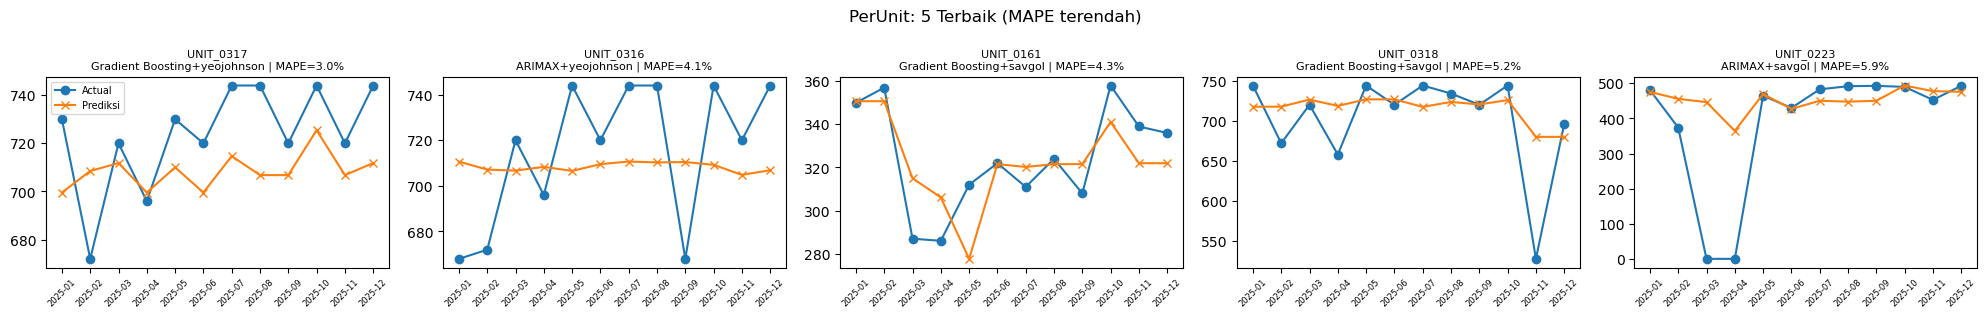

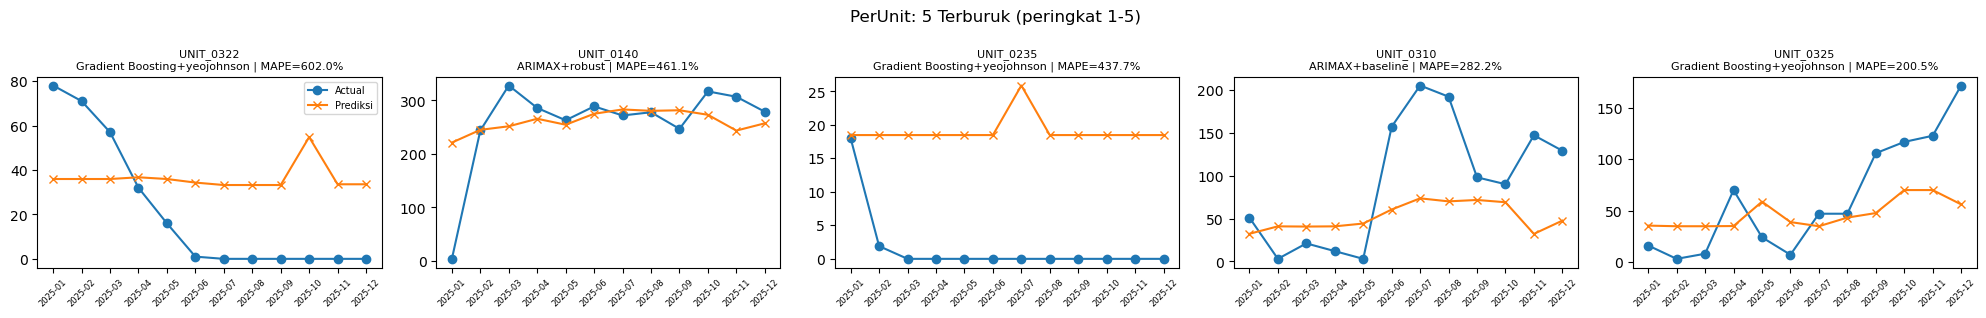

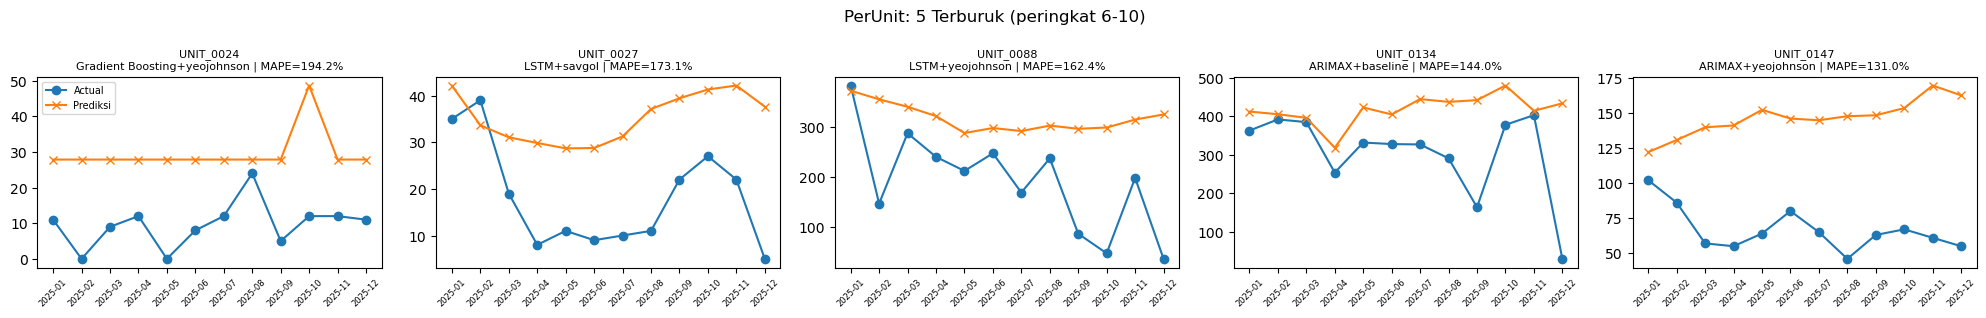

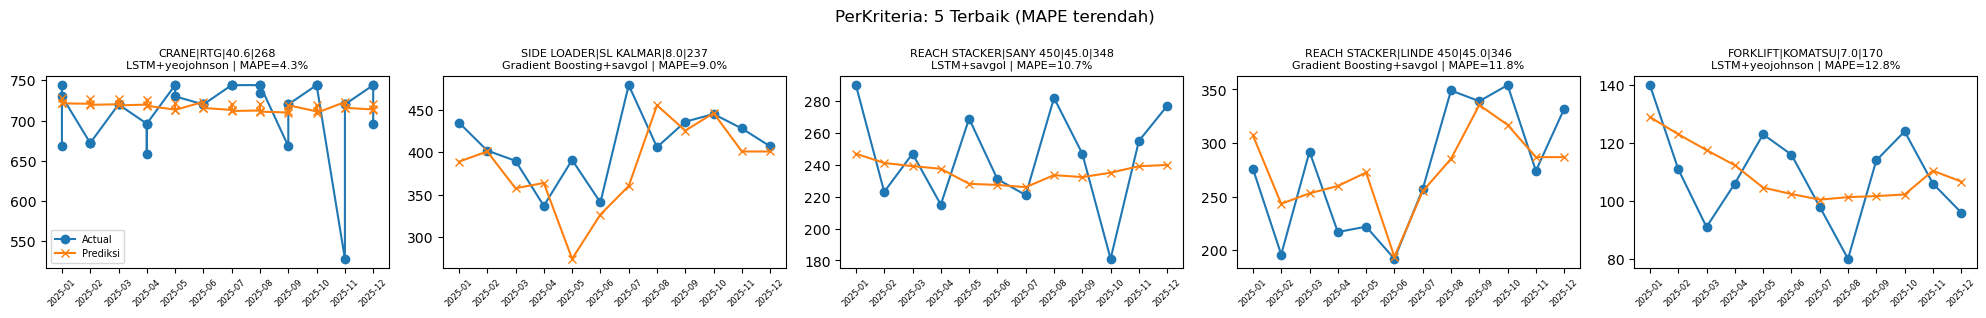

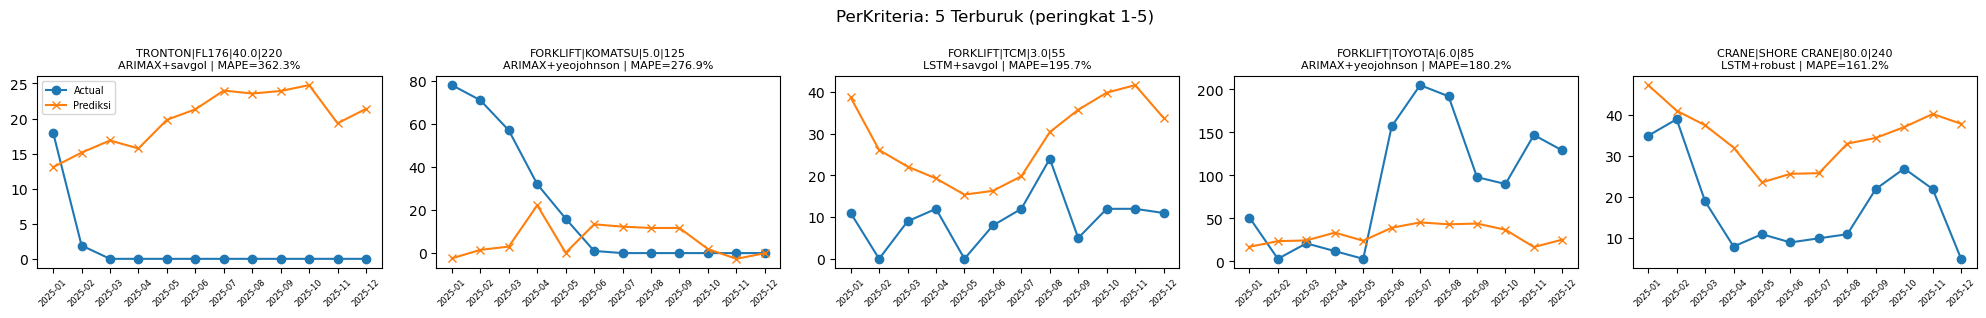

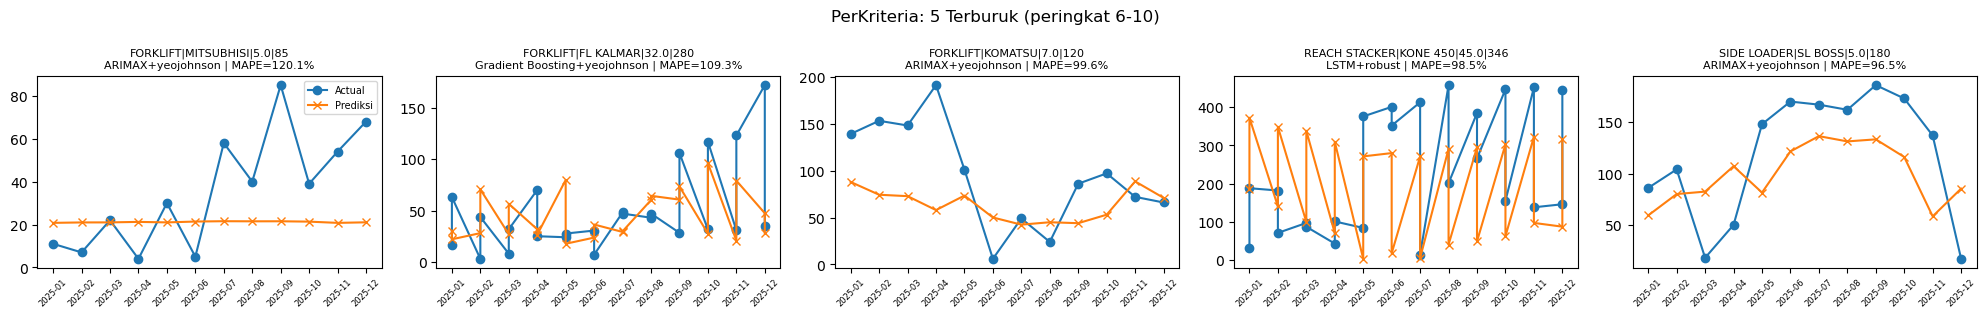

In [ ]:
def plot_group(df_subset, preds_all_df, group_col, title='', fname=None):
    n = len(df_subset)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 3.2))
    fig.suptitle(title, fontsize=12)
    if n == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, df_subset.iterrows()):
        g = row[group_col]
        sub = preds_all_df[(preds_all_df[group_col] == g) &
                            (preds_all_df['MODEL'] == row['MODEL']) &
                            (preds_all_df['VARIAN'] == row['VARIAN'])].sort_values('TAHUN_BULAN')
        ax.plot(sub['TAHUN_BULAN'].astype(str), sub['ACTUAL'], marker='o', label='Actual')
        ax.plot(sub['TAHUN_BULAN'].astype(str), sub['PRED'], marker='x', label='Prediksi')
        ax.set_title(f"{g}\n{row['MODEL']}+{row['VARIAN']} | MAPE={row['MAPE']:.1f}%", fontsize=8)
        ax.tick_params(axis='x', rotation=45, labelsize=6)
    axes[0].legend(fontsize=7)
    plt.tight_layout()
    if fname:
        plt.savefig(OUT_DIR / fname, dpi=150, bbox_inches='tight')
    plt.show()


def plot_best5_worst10_split(best_df, preds_all_df, group_col, label=''):
    ranked = best_df.sort_values('MAPE')
    best5 = ranked.head(5)
    worst10_desc = ranked.tail(10).sort_values('MAPE', ascending=False)
    worst_1_5 = worst10_desc.iloc[:5]
    worst_6_10 = worst10_desc.iloc[5:10]

    plot_group(best5, preds_all_df, group_col,
               title=f'{label}: 5 Terbaik (MAPE terendah)',
               fname=f'v2b_plot_{label.lower()}_best5.png')
    plot_group(worst_1_5, preds_all_df, group_col,
               title=f'{label}: 5 Terburuk (peringkat 1-5)',
               fname=f'v2b_plot_{label.lower()}_worst_1_5.png')
    plot_group(worst_6_10, preds_all_df, group_col,
               title=f'{label}: 5 Terburuk (peringkat 6-10)',
               fname=f'v2b_plot_{label.lower()}_worst_6_10.png')


plot_best5_worst10_split(best_per_unit, preds_unit_all, 'EQUIP NAME', label='PerUnit')
plot_best5_worst10_split(best_per_kriteria, preds_kriteria_all, 'KRITERIA_ID', label='PerKriteria')

# TAHAP 3 (Tuning Individual per Unit & per Kriteria)

**Model Terbaik dari Tahap 2 (kedua pendekatan):** Gradient Boosting + data-prep **savgol**.

Karena modelnya SAMA buat kedua pendekatan, cukup 1 jenis fungsi tuning (GB), dipakai 2x:
- **Per-unit**: tiap unit (227-an) dituning SENDIRI-SENDIRI (bukan 1 kombinasi global buat semua unit)
- **Per-kriteria**: tiap grup kriteria dituning SENDIRI-SENDIRI

Setelah itu baru dibandingin: prediksi gabungan (RMSE_GLOBAL) pakai parameter individual per-unit vs pakai parameter individual per-kriteria, yang jadi keputusan akhir pendekatan mana yang terpilih

In [32]:
# Siapkan data dengan data-prep SAVGOL (pemenang) — reuse fungsi dari Tahap 2
train_df_sg, test_df_sg, transformers_sg = prep_savgol(train_df_raw, test_df_raw)
train_full_sg = train_df_sg.merge(kriteria[['EQUIP NAME', 'KRITERIA_ID']], on='EQUIP NAME', how='left')
test_full_sg = test_df_sg.merge(kriteria[['EQUIP NAME', 'KRITERIA_ID']], on='EQUIP NAME', how='left')
train_lag_sg = make_lag_features(train_full_sg)
test_lag_all_sg = make_lag_features(pd.concat([train_full_sg, test_full_sg]))
test_lag_sg = test_lag_all_sg[test_lag_all_sg['TAHUN_BULAN'] >= TEST_START]

print(f'Data savgol siap: {len(unit_list)} unit, {len(kriteria_list)} kriteria')


Data savgol siap: 222 unit, 76 kriteria


## Tuning Individual Per-Unit

In [33]:
def tune_one_unit_gb(unit, gb_grid, gb_keys, train_lag, test_lag, transformers):
    best_rmse = np.inf
    best_row = None
    for combo in gb_grid:
        params = dict(zip(gb_keys, combo))
        g_train = train_lag[train_lag['EQUIP NAME'] == unit].dropna(subset=FEAT_COLS + ['UTILITAS_SMOOTH'])
        g_test = test_lag[test_lag['EQUIP NAME'] == unit].dropna(subset=FEAT_COLS)
        if len(g_train) < 6 or len(g_test) == 0:
            continue
        model = HistGradientBoostingRegressor(random_state=42, **params)
        model.fit(g_train[FEAT_COLS], g_train['UTILITAS_SMOOTH'])
        pred = model.predict(g_test[FEAT_COLS])
        pred = inverse_transform_pred(pred, unit, transformers)
        actual = g_test.set_index('TAHUN_BULAN')['UTILITAS'].reindex(g_test['TAHUN_BULAN']).values
        mape, rmse, bias = eval_pred(actual, pred)
        if not np.isnan(rmse) and rmse < best_rmse:
            best_rmse = rmse
            best_row = {'EQUIP NAME': unit, **params, 'MAPE': mape, 'RMSE': rmse, 'BIAS': bias}
    if best_row is None:
        best_row = {'EQUIP NAME': unit, **{k: np.nan for k in gb_keys}, 'MAPE': np.nan, 'RMSE': np.nan, 'BIAS': np.nan}
    return best_row


CKPT_UNIT_INDIVIDUAL = OUT_DIR / 'v3_gb_savgol_per_unit_individual_progress.csv'

done_units = set(pd.read_csv(CKPT_UNIT_INDIVIDUAL)['EQUIP NAME']) if CKPT_UNIT_INDIVIDUAL.exists() else set()
remaining_units = [u for u in unit_list if u not in done_units]
print(f'{len(remaining_units)} unit tersisa dari {len(unit_list)} buat tuning individual')

if remaining_units:
    with Parallel(n_jobs=N_JOBS) as parallel:
        for i in range(0, len(remaining_units), BATCH_SIZE):
            batch = remaining_units[i:i + BATCH_SIZE]
            res = parallel(delayed(tune_one_unit_gb)(u, gb_grid, gb_keys, train_lag_sg, test_lag_sg, transformers_sg) for u in batch)
            pd.DataFrame(res).to_csv(CKPT_UNIT_INDIVIDUAL, mode='a', header=not CKPT_UNIT_INDIVIDUAL.exists(), index=False)
            _progress('tuning per-unit individual', i + len(batch), len(remaining_units), i // BATCH_SIZE)

per_unit_individual = pd.read_csv(CKPT_UNIT_INDIVIDUAL)
print(f"\nSelesai. Rata-rata RMSE per-unit (individual): {per_unit_individual['RMSE'].mean():.2f}")
print(f"Median RMSE per-unit (individual): {per_unit_individual['RMSE'].median():.2f}")


0 unit tersisa dari 222 buat tuning individual

Selesai. Rata-rata RMSE per-unit (individual): 54.89
Median RMSE per-unit (individual): 42.47


### Refit Final Per-Unit

In [34]:
def refit_gb_unit_individual(row, train_lag, test_lag, transformers):
    unit = row['EQUIP NAME']
    if pd.isna(row['RMSE']):
        return []
    params = {k: row[k] for k in gb_keys}
    if pd.notna(params.get('max_depth')):
        params['max_depth'] = int(params['max_depth'])
    else:
        params['max_depth'] = None
    params['max_iter'] = int(params['max_iter'])
    params['min_samples_leaf'] = int(params['min_samples_leaf'])

    g_train = train_lag[train_lag['EQUIP NAME'] == unit].dropna(subset=FEAT_COLS + ['UTILITAS_SMOOTH'])
    g_test = test_lag[test_lag['EQUIP NAME'] == unit].dropna(subset=FEAT_COLS)
    if len(g_train) < 6 or len(g_test) == 0:
        return []
    model = HistGradientBoostingRegressor(random_state=42, **params)
    model.fit(g_train[FEAT_COLS], g_train['UTILITAS_SMOOTH'])
    pred = model.predict(g_test[FEAT_COLS])
    pred = inverse_transform_pred(pred, unit, transformers)
    actual = g_test.set_index('TAHUN_BULAN')['UTILITAS'].reindex(g_test['TAHUN_BULAN'])
    return [{'EQUIP NAME': unit, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p}
            for t, a, p in zip(g_test['TAHUN_BULAN'].values, actual.values, pred)]


all_preds_unit_individual = []
for _, row in per_unit_individual.iterrows():
    all_preds_unit_individual.extend(refit_gb_unit_individual(row, train_lag_sg, test_lag_sg, transformers_sg))

preds_unit_individual_df = pd.DataFrame(all_preds_unit_individual)
metrics_unit_individual = global_metrics(preds_unit_individual_df)

print('=== HASIL AKHIR — Pendekatan PER-UNIT (parameter individual tiap unit) ===')
print(f"RMSE_GLOBAL = {metrics_unit_individual['RMSE_GLOBAL']:.2f}")
print(f"BIAS_GLOBAL = {metrics_unit_individual['BIAS_GLOBAL']:+.2f}")
print(f"MAPE_GLOBAL = {metrics_unit_individual['MAPE_GLOBAL']:.2f}%")

per_unit_individual.to_csv(OUT_DIR / 'v3_final_params_per_unit_individual.csv', index=False)
preds_unit_individual_df.to_csv(OUT_DIR / 'v3_final_preds_per_unit_individual.csv', index=False)


=== HASIL AKHIR — Pendekatan PER-UNIT (parameter individual tiap unit) ===
RMSE_GLOBAL = 69.15
BIAS_GLOBAL = -1.47
MAPE_GLOBAL = 41.44%


## Tuning Individual Per-Kriteria

In [35]:
def tune_one_kriteria_gb(k, gb_grid, gb_keys, train_lag, test_lag, transformers):
    best_rmse = np.inf
    best_row = None
    for combo in gb_grid:
        params = dict(zip(gb_keys, combo))
        g_train = train_lag[train_lag['KRITERIA_ID'] == k].dropna(subset=FEAT_COLS + ['UTILITAS_SMOOTH'])
        g_test = test_lag[test_lag['KRITERIA_ID'] == k].dropna(subset=FEAT_COLS)
        if len(g_train) < 6 or len(g_test) == 0:
            continue
        model = HistGradientBoostingRegressor(random_state=42, **params)
        model.fit(g_train[FEAT_COLS], g_train['UTILITAS_SMOOTH'])
        pred_all = model.predict(g_test[FEAT_COLS])
        preds_rows = []
        for unit, g_unit_test in g_test.groupby('EQUIP NAME'):
            mask = (g_test['EQUIP NAME'] == unit).values
            pred_u = inverse_transform_pred(pred_all[mask], unit, transformers)
            actual = g_unit_test.set_index('TAHUN_BULAN')['UTILITAS'].reindex(g_unit_test['TAHUN_BULAN'])
            for a, p in zip(actual.values, pred_u):
                preds_rows.append({'ACTUAL': a, 'PRED': p})
        preds_df = pd.DataFrame(preds_rows)
        m = global_metrics(preds_df)
        if not np.isnan(m['RMSE_GLOBAL']) and m['RMSE_GLOBAL'] < best_rmse:
            best_rmse = m['RMSE_GLOBAL']
            best_row = {'KRITERIA_ID': k, **params, 'RMSE': m['RMSE_GLOBAL'], 'BIAS': m['BIAS_GLOBAL'],
                        'MAPE': m['MAPE_GLOBAL'], 'n_unit': g_test['EQUIP NAME'].nunique()}
    if best_row is None:
        best_row = {'KRITERIA_ID': k, **{kk: np.nan for kk in gb_keys}, 'RMSE': np.nan, 'BIAS': np.nan,
                     'MAPE': np.nan, 'n_unit': 0}
    return best_row


CKPT_KRITERIA_INDIVIDUAL = OUT_DIR / 'v3_gb_savgol_per_kriteria_individual_progress.csv'

done_kriteria = set(pd.read_csv(CKPT_KRITERIA_INDIVIDUAL)['KRITERIA_ID']) if CKPT_KRITERIA_INDIVIDUAL.exists() else set()
remaining_kriteria = [k for k in kriteria_list if k not in done_kriteria]
print(f'{len(remaining_kriteria)} kriteria tersisa dari {len(kriteria_list)} buat tuning individual')

if remaining_kriteria:
    with Parallel(n_jobs=N_JOBS) as parallel:
        for i in range(0, len(remaining_kriteria), BATCH_SIZE):
            batch = remaining_kriteria[i:i + BATCH_SIZE]
            res = parallel(delayed(tune_one_kriteria_gb)(k, gb_grid, gb_keys, train_lag_sg, test_lag_sg, transformers_sg) for k in batch)
            pd.DataFrame(res).to_csv(CKPT_KRITERIA_INDIVIDUAL, mode='a', header=not CKPT_KRITERIA_INDIVIDUAL.exists(), index=False)
            _progress('tuning per-kriteria individual', i + len(batch), len(remaining_kriteria), i // BATCH_SIZE)

per_kriteria_individual = pd.read_csv(CKPT_KRITERIA_INDIVIDUAL)
print(f"\nSelesai. Rata-rata RMSE per-kriteria (individual): {per_kriteria_individual['RMSE'].mean():.2f}")
print(f"Median RMSE per-kriteria (individual): {per_kriteria_individual['RMSE'].median():.2f}")

0 kriteria tersisa dari 76 buat tuning individual

Selesai. Rata-rata RMSE per-kriteria (individual): 42.65
Median RMSE per-kriteria (individual): 31.58


### Refit Final Per-Kriteria

In [36]:
def refit_gb_kriteria_individual(row, train_lag, test_lag, transformers):
    k = row['KRITERIA_ID']
    if pd.isna(row['RMSE']):
        return []
    params = {kk: row[kk] for kk in gb_keys}
    if pd.notna(params.get('max_depth')):
        params['max_depth'] = int(params['max_depth'])
    else:
        params['max_depth'] = None
    params['max_iter'] = int(params['max_iter'])
    params['min_samples_leaf'] = int(params['min_samples_leaf'])

    g_train = train_lag[train_lag['KRITERIA_ID'] == k].dropna(subset=FEAT_COLS + ['UTILITAS_SMOOTH'])
    g_test = test_lag[test_lag['KRITERIA_ID'] == k].dropna(subset=FEAT_COLS)
    if len(g_train) < 6 or len(g_test) == 0:
        return []
    model = HistGradientBoostingRegressor(random_state=42, **params)
    model.fit(g_train[FEAT_COLS], g_train['UTILITAS_SMOOTH'])
    pred_all = model.predict(g_test[FEAT_COLS])
    rows = []
    for unit, g_unit_test in g_test.groupby('EQUIP NAME'):
        mask = (g_test['EQUIP NAME'] == unit).values
        pred_u = inverse_transform_pred(pred_all[mask], unit, transformers)
        actual = g_unit_test.set_index('TAHUN_BULAN')['UTILITAS'].reindex(g_unit_test['TAHUN_BULAN'])
        for t, a, p in zip(g_unit_test['TAHUN_BULAN'].values, actual.values, pred_u):
            rows.append({'EQUIP NAME': unit, 'KRITERIA_ID': k, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
    return rows


all_preds_kriteria_individual = []
for _, row in per_kriteria_individual.iterrows():
    all_preds_kriteria_individual.extend(refit_gb_kriteria_individual(row, train_lag_sg, test_lag_sg, transformers_sg))

preds_kriteria_individual_df = pd.DataFrame(all_preds_kriteria_individual)
metrics_kriteria_individual = global_metrics(preds_kriteria_individual_df)

print('=== HASIL AKHIR — Pendekatan PER-KRITERIA (parameter individual tiap kriteria) ===')
print(f"RMSE_GLOBAL = {metrics_kriteria_individual['RMSE_GLOBAL']:.2f}")
print(f"BIAS_GLOBAL = {metrics_kriteria_individual['BIAS_GLOBAL']:+.2f}")
print(f"MAPE_GLOBAL = {metrics_kriteria_individual['MAPE_GLOBAL']:.2f}%")

per_kriteria_individual.to_csv(OUT_DIR / 'v3_final_params_per_kriteria_individual.csv', index=False)
preds_kriteria_individual_df.to_csv(OUT_DIR / 'v3_final_preds_per_kriteria_individual.csv', index=False)

=== HASIL AKHIR — Pendekatan PER-KRITERIA (parameter individual tiap kriteria) ===
RMSE_GLOBAL = 56.77
BIAS_GLOBAL = -3.11
MAPE_GLOBAL = 38.21%


### KESIMPULAN FINAL Per-Unit vs Per-Kriteria (Parameter Individual)

In [37]:
final_comparison = pd.DataFrame([
    {'PENDEKATAN': 'per-unit (individual)', 'RMSE_GLOBAL': metrics_unit_individual['RMSE_GLOBAL'],
     'BIAS_GLOBAL': metrics_unit_individual['BIAS_GLOBAL'], 'MAPE_GLOBAL': metrics_unit_individual['MAPE_GLOBAL'],
     'N_GROUP': len(per_unit_individual)},
    {'PENDEKATAN': 'per-kriteria (individual)', 'RMSE_GLOBAL': metrics_kriteria_individual['RMSE_GLOBAL'],
     'BIAS_GLOBAL': metrics_kriteria_individual['BIAS_GLOBAL'], 'MAPE_GLOBAL': metrics_kriteria_individual['MAPE_GLOBAL'],
     'N_GROUP': len(per_kriteria_individual)},
]).sort_values('RMSE_GLOBAL').reset_index(drop=True)

print('=== PERBANDINGAN FINAL: Per-Unit vs Per-Kriteria (parameter individual, model GB+savgol) ===')
print(final_comparison.to_string(index=False))

pemenang_final = final_comparison.iloc[0]
print(f"\n>>> PENDEKATAN TERBAIK FINAL: {pemenang_final['PENDEKATAN']}")
print(f"    RMSE_GLOBAL={pemenang_final['RMSE_GLOBAL']:.2f} | BIAS={pemenang_final['BIAS_GLOBAL']:+.2f} | MAPE={pemenang_final['MAPE_GLOBAL']:.2f}%")

final_comparison.to_csv(OUT_DIR / 'v3_KESIMPULAN_FINAL_per_unit_vs_per_kriteria.csv', index=False)


=== PERBANDINGAN FINAL: Per-Unit vs Per-Kriteria (parameter individual, model GB+savgol) ===
               PENDEKATAN  RMSE_GLOBAL  BIAS_GLOBAL  MAPE_GLOBAL  N_GROUP
per-kriteria (individual)    56.767597    -3.113763    38.208168       76
    per-unit (individual)    69.151957    -1.469552    41.442407      222

>>> PENDEKATAN TERBAIK FINAL: per-kriteria (individual)
    RMSE_GLOBAL=56.77 | BIAS=-3.11 | MAPE=38.21%


### Plot 3 Terbaik & 3 Terburuk dari Pendekatan Terbaik

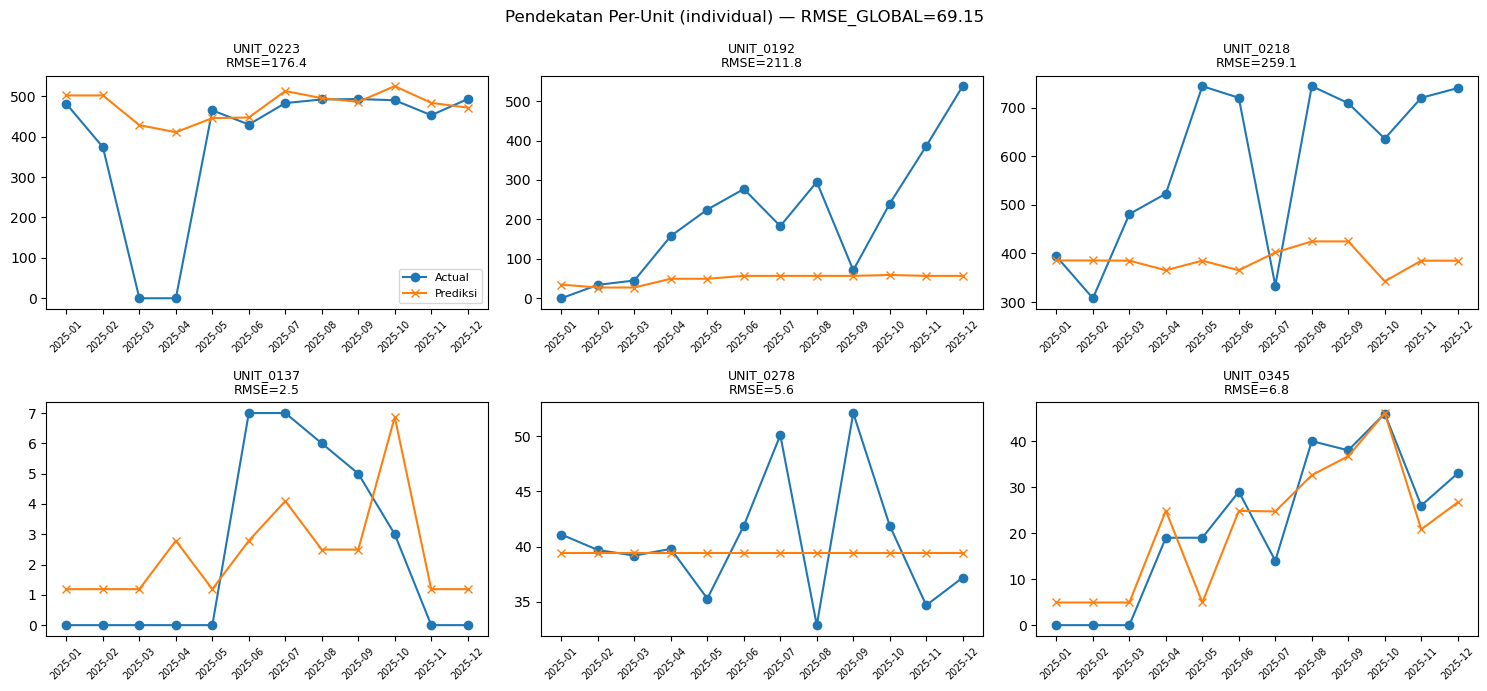

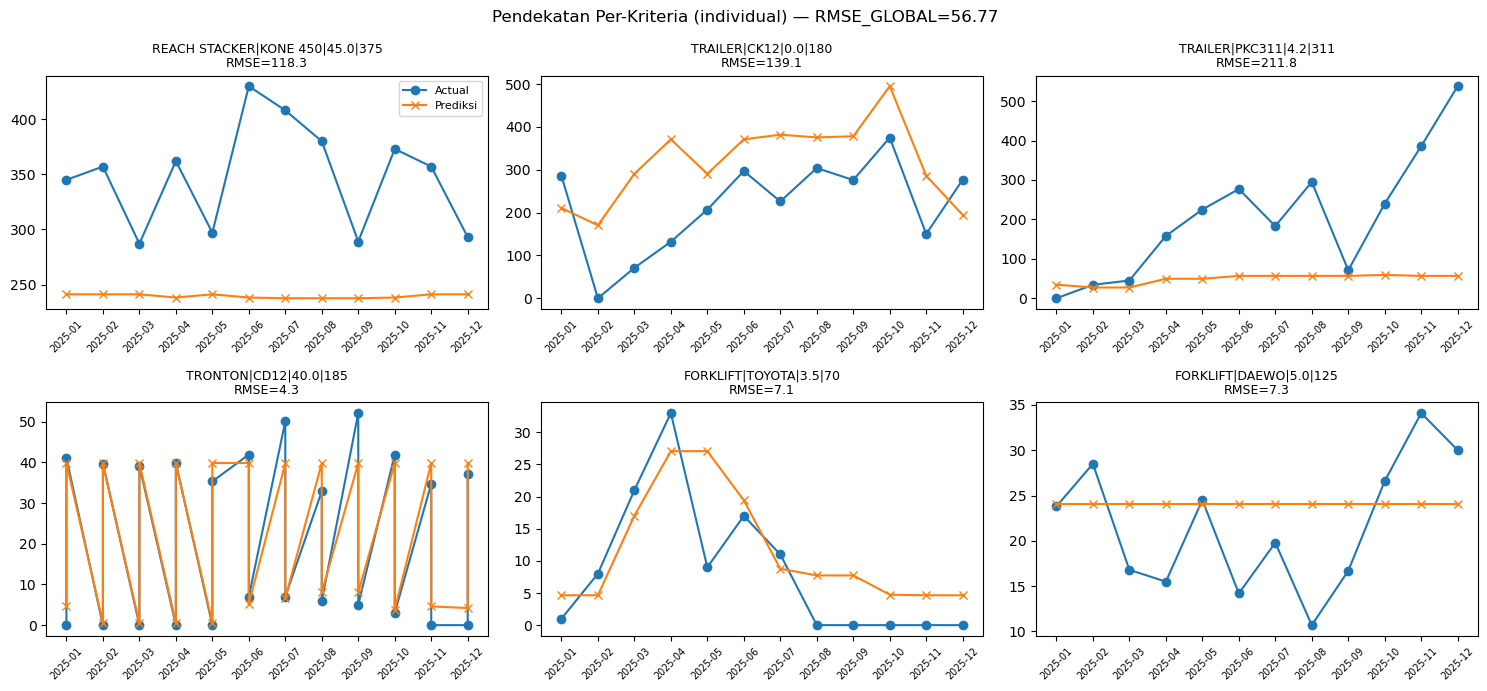

In [38]:
import matplotlib.pyplot as plt


def plot_top_bottom_mape(results_df, preds_df, title, unit_col='EQUIP NAME', metric_col='RMSE', fname=None):
    ranked = results_df.dropna(subset=[metric_col]).sort_values(metric_col)
    worst3 = ranked.tail(3)[unit_col].tolist()
    best3 = ranked.head(3)[unit_col].tolist()
    picks = worst3 + best3

    fig, axes = plt.subplots(2, 3, figsize=(15, 7))
    fig.suptitle(title, fontsize=12)
    for ax, u in zip(axes.flat, picks):
        sub = preds_df[preds_df[unit_col] == u].sort_values('TAHUN_BULAN')
        ax.plot(sub['TAHUN_BULAN'].astype(str), sub['ACTUAL'], marker='o', label='Actual')
        ax.plot(sub['TAHUN_BULAN'].astype(str), sub['PRED'], marker='x', label='Prediksi')
        rmse_val = ranked[ranked[unit_col] == u][metric_col].values[0]
        ax.set_title(f'{u}\nRMSE={rmse_val:.1f}', fontsize=9)
        ax.tick_params(axis='x', rotation=45, labelsize=7)
        if ax is axes.flat[0]:
            ax.legend(fontsize=8)
    plt.tight_layout()
    if fname:
        plt.savefig(OUT_DIR / fname, dpi=150)
    plt.show()


plot_top_bottom_mape(per_unit_individual, preds_unit_individual_df,
                      f"Pendekatan Per-Unit (individual) — RMSE_GLOBAL={metrics_unit_individual['RMSE_GLOBAL']:.2f}",
                      unit_col='EQUIP NAME', fname='v3_plot_per_unit_individual.png')

plot_top_bottom_mape(per_kriteria_individual, preds_kriteria_individual_df,
                      f"Pendekatan Per-Kriteria (individual) — RMSE_GLOBAL={metrics_kriteria_individual['RMSE_GLOBAL']:.2f}",
                      unit_col='KRITERIA_ID', fname='v3_plot_per_kriteria_individual.png')
